# Dataset 1

In [1]:
import pandas as pd
import numpy as np

def load_behrenfeld_file(filepath, label=None):
    """
    Load a Behrenfeld-Falkowski style .txt file.
    
    filepath : path to the .txt file
    """
    # Read raw lines, skip the $$$ header block
    with open(filepath, 'r') as f:
        lines = f.readlines()
    
    # Find the line where actual column headers start COUNT
    dataStartIdx = None
    for i, line in enumerate(lines):
        if line.strip().startswith('Count'):
            dataStartIdx = i
            break
    
    if dataStartIdx is None:
        raise ValueError(f"Could not find header row in file: {filepath}")
    
    # Parse tab-separated data, starting from the header row
    from io import StringIO
    rawData = ''.join(lines[dataStartIdx:])
    
    df = pd.read_csv(
        StringIO(rawData),
        sep='\t',
        dtype=str       # read everything as string first to handle mixed types
    )
    
    # Clean up column names
    df.columns = df.columns.str.strip()
    
    # Replace empty strings with NaN so ffill works properly
    df.replace('', np.nan, inplace=True)
    
    # Forward-fill the "parent station" columns
    # These are the columns that only appear in the FIRST row of each station
    stationCols = ['Criuse', 'Day', 'Month', 'Year', 'LAT', 'LONG', 
                   'Temp D', 'ayLengh', 'Irr', 'Pb_opt']
    
    for col in stationCols:
        if col in df.columns:
            df[col] = df[col].ffill()
    
    # Drop completely blank rows (the separator rows)
    df.dropna(how='all', inplace=True)
    
    # Drop rows where ALL the important columns are NaN
    df.dropna(subset=['Depth'], inplace=True)
    
    # Convert numeric columns to float
    numericCols = ['Count', 'Day', 'Month', 'Year', 'LAT', 'LONG',
                   'Temp D', 'ayLengh', 'Irr', 'Pb_opt',
                   'Depth', '%Irr', 'O.D.', 'Chl', 'Pb', 'PP', 'IPP']
    
    for col in numericCols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
        
    
    return df


# Dataframe for file 1
df1 = load_behrenfeld_file(
    r"C:\ResearchData\Behrenfeld_Falkowski 1.txt",
    label='dataset_1'
)

print(df1.shape)
print(df1.head(10))
print(df1.dtypes)

(1165, 18)
    Count    Criuse  Day  Month  Year    LAT   LONG  Temp D  ayLengh   Irr  \
0       1  Albatros   16      3  1979  38.78 -72.27     7.0    11.82  6.23   
1       2  Albatros   16      3  1979  38.78 -72.27     7.0    11.82  6.23   
2       3  Albatros   16      3  1979  38.78 -72.27     7.0    11.82  6.23   
3       4  Albatros   16      3  1979  38.78 -72.27     7.0    11.82  6.23   
4       5  Albatros   16      3  1979  38.78 -72.27     7.0    11.82  6.23   
5       6  Albatros   16      3  1979  38.78 -72.27     7.0    11.82  6.23   
7       8  Albatros   17      3  1979  39.50 -73.43     4.0    11.86  9.87   
8       9  Albatros   17      3  1979  39.50 -73.43     4.0    11.86  9.87   
9      10  Albatros   17      3  1979  39.50 -73.43     4.0    11.86  9.87   
10     11  Albatros   17      3  1979  39.50 -73.43     4.0    11.86  9.87   

    Pb_opt  Depth  %Irr  O.D.   Chl    Pb      PP     IPP  
0     5.03   0.00   100  0.00  2.72  3.92  126.00  1775.3  
1     5.03

In [2]:
df1.columns

Index(['Count', 'Criuse', 'Day', 'Month', 'Year', 'LAT', 'LONG', 'Temp D',
       'ayLengh', 'Irr', 'Pb_opt', 'Depth', '%Irr', 'O.D.', 'Chl', 'Pb', 'PP',
       'IPP'],
      dtype='str')

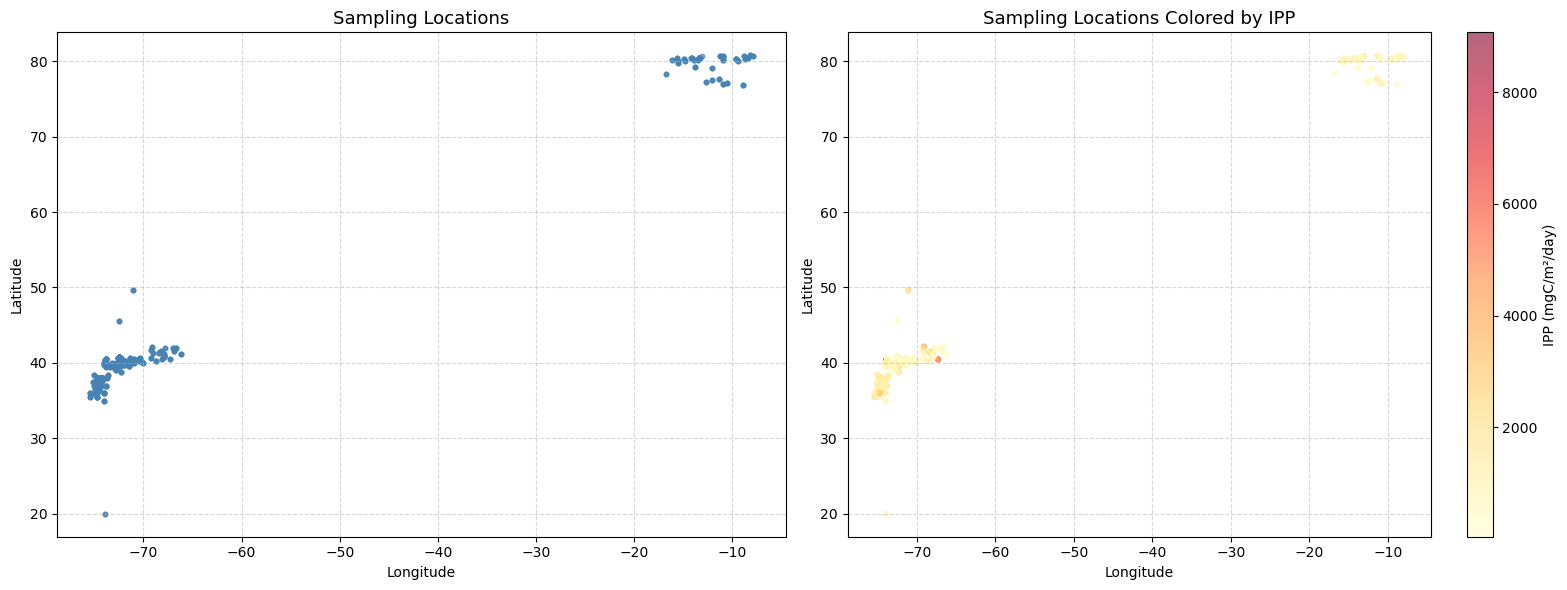

In [3]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# just locations graph 1
axes[0].scatter(
    df1['LONG'], 
    df1['LAT'],
    alpha=0.4, 
    s=10, 
    color='steelblue'
)
axes[0].set_title('Sampling Locations', fontsize=13)
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Color by IPP graph 2
# Only rows where IPP is not NaN
# reddish dots = high productivity areas, yellowish = low
'''
Yellow dot = location has low IPP = less productive ocean
Red dot = location has high IPP = more productive ocean
'''
dfIpp = df1.dropna(subset=['IPP'])

scatter = axes[1].scatter(
    dfIpp['LONG'],
    dfIpp['LAT'],
    c=dfIpp['IPP'],        
    cmap='YlOrRd',    
    alpha=0.6,
    s=15
)
plt.colorbar(scatter, ax=axes[1], label='IPP (mgC/m²/day)')
axes[1].set_title('Sampling Locations Colored by IPP', fontsize=13)
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Dataset 2

In [4]:
import pandas as pd
import numpy as np

def load_behrenfeld_file(filepath, label=None):
    """
    Load a Behrenfeld-Falkowski style .txt file.
    
    filepath : path to the .txt file
    """
    # Read raw lines, skip the $$$ header block
    with open(filepath, 'r') as f:
        lines = f.readlines()
    
    # Find the line where actual column headers start COUNT
    dataStartIdx = None
    for i, line in enumerate(lines):
        if line.strip().startswith('Count'):
            dataStartIdx = i
            break
    
    if dataStartIdx is None:
        raise ValueError(f"Could not find header row in file: {filepath}")
    
    # Parse tab-separated data, starting from the header row
    from io import StringIO
    rawData = ''.join(lines[dataStartIdx:])
    
    df = pd.read_csv(
        StringIO(rawData),
        sep='\t',
        dtype=str       # read everything as string first to handle mixed types
    )
    
    # Clean up column names
    df.columns = df.columns.str.strip()
    
    # Replace empty strings with NaN so ffill works properly
    df.replace('', np.nan, inplace=True)
    
    # Forward-fill the "parent station" columns
    # These are the columns that only appear in the FIRST row of each station
    stationCols = ['Criuse', 'Day', 'Month', 'Year', 'LAT', 'LONG', 
                   'Temp D', 'ayLengh', 'Irr', 'Pb_opt']
    
    for col in stationCols:
        if col in df.columns:
            df[col] = df[col].ffill()
    
    # Drop completely blank rows (the separator rows)
    df.dropna(how='all', inplace=True)
    
    # Drop rows where ALL the important columns are NaN
    df.dropna(subset=['Depth'], inplace=True)
    
    # Convert numeric columns to float
    numericCols = ['Count', 'Day', 'Month', 'Year', 'LAT', 'LONG',
                   'Temp D', 'ayLengh', 'Irr', 'Pb_opt',
                   'Depth', '%Irr', 'O.D.', 'Chl', 'Pb', 'PP', 'IPP']
    
    for col in numericCols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
        
    
    return df


# Dataframe for file 1
df2 = load_behrenfeld_file(
    r"C:\ResearchData\Babin 2.txt",
    label='dataset_2'
)

print(df2.shape)
print(df2.head(10))
print(df2.dtypes)

(71, 18)
    Count  Criuse  Day  Month  Year    LAT   LONG  Temp D  ayLengh    Irr  \
0    1376  Eumeli   13      6  1992  20.54 -18.57    17.8    13.23  60.46   
1    1377  Eumeli   13      6  1992  20.54 -18.57    17.8    13.23  60.46   
2    1378  Eumeli   13      6  1992  20.54 -18.57    17.8    13.23  60.46   
3    1379  Eumeli   13      6  1992  20.54 -18.57    17.8    13.23  60.46   
4    1380  Eumeli   13      6  1992  20.54 -18.57    17.8    13.23  60.46   
6    1382  Eumeli   14      6  1992  20.53 -18.56    18.0    13.24  60.46   
7    1383  Eumeli   14      6  1992  20.53 -18.56    18.0    13.24  60.46   
8    1384  Eumeli   14      6  1992  20.53 -18.56    18.0    13.24  60.46   
9    1385  Eumeli   14      6  1992  20.53 -18.56    18.0    13.24  60.46   
10   1386  Eumeli   14      6  1992  20.53 -18.56    18.0    13.24  60.46   

    Pb_opt  Depth  %Irr  O.D.   Chl    Pb      PP     IPP  
0      5.1      2    60  0.51  4.34  2.32  132.86  2620.7  
1      5.1      5    28

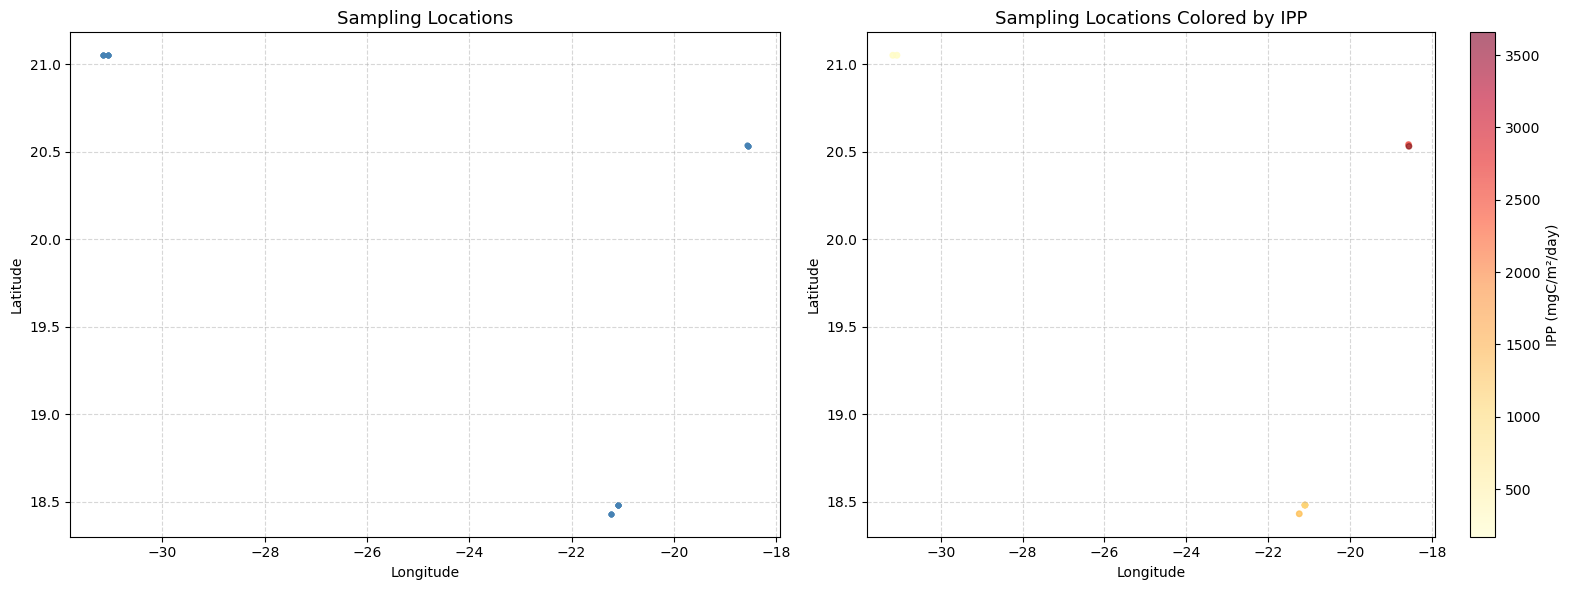

In [5]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# just locations graph 1
axes[0].scatter(
    df2['LONG'], 
    df2['LAT'],
    alpha=0.4, 
    s=10, 
    color='steelblue'
)
axes[0].set_title('Sampling Locations', fontsize=13)
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Color by IPP graph 2
# Only rows where IPP is not NaN
# reddish dots = high productivity areas, yellowish = low
'''
Yellow dot = location has low IPP = less productive ocean
Red dot = location has high IPP = more productive ocean
'''
dfIpp = df2.dropna(subset=['IPP'])

scatter = axes[1].scatter(
    dfIpp['LONG'],
    dfIpp['LAT'],
    c=dfIpp['IPP'],        
    cmap='YlOrRd',    
    alpha=0.6,
    s=15
)
plt.colorbar(scatter, ax=axes[1], label='IPP (mgC/m²/day)')
axes[1].set_title('Sampling Locations Colored by IPP', fontsize=13)
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Dataset 3

In [6]:
import pandas as pd
import numpy as np

def load_behrenfeld_file(filepath, label=None):
    """
    Load a Behrenfeld-Falkowski style .txt file.
    
    filepath : path to the .txt file
    """
    # Read raw lines, skip the $$$ header block
    with open(filepath, 'r') as f:
        lines = f.readlines()
    
    # Find the line where actual column headers start COUNT
    dataStartIdx = None
    for i, line in enumerate(lines):
        if line.strip().startswith('Count'):
            dataStartIdx = i
            break
    
    if dataStartIdx is None:
        raise ValueError(f"Could not find header row in file: {filepath}")
    
    # Parse tab-separated data, starting from the header row
    from io import StringIO
    rawData = ''.join(lines[dataStartIdx:])
    
    df = pd.read_csv(
        StringIO(rawData),
        sep='\t',
        dtype=str       # read everything as string first to handle mixed types
    )
    
    # Clean up column names
    df.columns = df.columns.str.strip()
    
    # Replace empty strings with NaN so ffill works properly
    df.replace('', np.nan, inplace=True)
    
    # Forward-fill the "parent station" columns
    # These are the columns that only appear in the FIRST row of each station
    stationCols = ['Criuse', 'Day', 'Month', 'Year', 'LAT', 'LONG', 
                   'Temp D', 'ayLengh', 'Irr', 'Pb_opt']
    
    for col in stationCols:
        if col in df.columns:
            df[col] = df[col].ffill()
    
    # Drop completely blank rows (the separator rows)
    df.dropna(how='all', inplace=True)
    
    # Drop rows where ALL the important columns are NaN
    df.dropna(subset=['Depth'], inplace=True)
    
    # Convert numeric columns to float
    numericCols = ['Count', 'Day', 'Month', 'Year', 'LAT', 'LONG',
                   'Temp D', 'ayLengh', 'Irr', 'Pb_opt',
                   'Depth', '%Irr', 'O.D.', 'Chl', 'Pb', 'PP', 'IPP']
    
    for col in numericCols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
        
    
    return df


# Dataframe for file 1
df3 = load_behrenfeld_file(
    r"C:\ResearchData\Karl 3.txt",
    label='dataset_3'
)

print(df3.shape)
print(df3.head(10))
print(df3.dtypes)

(249, 18)
    Count Criuse  Day  Month  Year   LAT  LONG  Temp D  ayLengh   Irr  Pb_opt  \
0    1460   HOTS   26    3.0  1989  21.2   NaN     NaN    12.85  41.9     5.8   
1    1461   HOTS   26    3.0  1989  21.2   NaN     NaN    12.85  41.9     5.8   
2    1462   HOTS   26    3.0  1989  21.2   NaN     NaN    12.85  41.9     5.8   
3    1463   HOTS   26    3.0  1989  21.2   NaN     NaN    12.85  41.9     5.8   
4    1464   HOTS   26    3.0  1989  21.2   NaN     NaN    12.85  41.9     5.8   
6    1466   HOTS    2    NaN  1989  21.0   NaN     NaN    12.28  52.0     NaN   
7    1467   HOTS    2    NaN  1989  21.0   NaN     NaN    12.28  52.0     NaN   
8    1468   HOTS    2    NaN  1989  21.0   NaN     NaN    12.28  52.0     NaN   
9    1469   HOTS    2    NaN  1989  21.0   NaN     NaN    12.28  52.0     NaN   
10   1470   HOTS    2    NaN  1989  21.0   NaN     NaN    12.28  52.0     NaN   

    Depth  %Irr  O.D.   Chl    Pb    PP    IPP  
0       5  83.0  0.18  0.09  1.74  1.92  284.6  


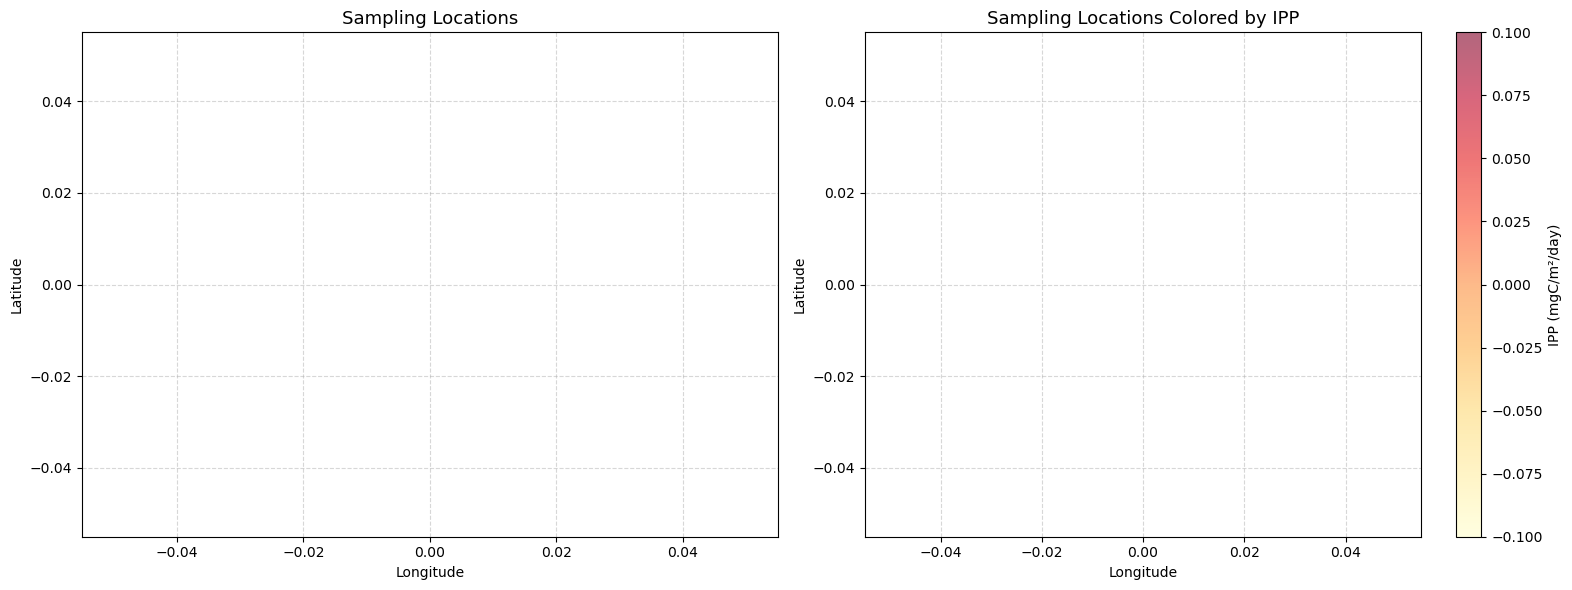

In [7]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# just locations graph 1
axes[0].scatter(
    df3['LONG'], 
    df3['LAT'],
    alpha=0.4, 
    s=10, 
    color='steelblue'
)
axes[0].set_title('Sampling Locations', fontsize=13)
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Color by IPP graph 2
# Only rows where IPP is not NaN
# reddish dots = high productivity areas, yellowish = low
'''
Yellow dot = location has low IPP = less productive ocean
Red dot = location has high IPP = more productive ocean
'''
dfIpp = df3.dropna(subset=['IPP'])

scatter = axes[1].scatter(
    dfIpp['LONG'],
    dfIpp['LAT'],
    c=dfIpp['IPP'],        
    cmap='YlOrRd',    
    alpha=0.6,
    s=15
)
plt.colorbar(scatter, ax=axes[1], label='IPP (mgC/m²/day)')
axes[1].set_title('Sampling Locations Colored by IPP', fontsize=13)
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Dataset 4

In [8]:
import pandas as pd
import numpy as np

def load_behrenfeld_file(filepath, label=None):
    """
    Load a Behrenfeld-Falkowski style .txt file.
    
    filepath : path to the .txt file
    """
    # Read raw lines, skip the $$$ header block
    with open(filepath, 'r') as f:
        lines = f.readlines()
    
    # Find the line where actual column headers start COUNT
    dataStartIdx = None
    for i, line in enumerate(lines):
        if line.strip().startswith('Count'):
            dataStartIdx = i
            break
    
    if dataStartIdx is None:
        raise ValueError(f"Could not find header row in file: {filepath}")
    
    # Parse tab-separated data, starting from the header row
    from io import StringIO
    rawData = ''.join(lines[dataStartIdx:])
    
    df = pd.read_csv(
        StringIO(rawData),
        sep='\t',
        dtype=str       # read everything as string first to handle mixed types
    )
    
    # Clean up column names
    df.columns = df.columns.str.strip()
    
    # Replace empty strings with NaN so ffill works properly
    df.replace('', np.nan, inplace=True)
    
    # Forward-fill the "parent station" columns
    # These are the columns that only appear in the FIRST row of each station
    stationCols = ['Criuse', 'Day', 'Month', 'Year', 'LAT', 'LONG', 
                   'Temp D', 'ayLengh', 'Irr', 'Pb_opt']
    
    for col in stationCols:
        if col in df.columns:
            df[col] = df[col].ffill()
    
    # Drop completely blank rows (the separator rows)
    df.dropna(how='all', inplace=True)
    
    # Drop rows where ALL the important columns are NaN
    df.dropna(subset=['Depth'], inplace=True)
    
    # Convert numeric columns to float
    numericCols = ['Count', 'Day', 'Month', 'Year', 'LAT', 'LONG',
                   'Temp D', 'ayLengh', 'Irr', 'Pb_opt',
                   'Depth', '%Irr', 'O.D.', 'Chl', 'Pb', 'PP', 'IPP']
    
    for col in numericCols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
        
    
    return df


# Dataframe for file 1
df4 = load_behrenfeld_file(
    r"C:\ResearchData\Barber 4.txt",
    label='dataset_4'
)

print(df4.shape)
print(df4.head(10))
print(df4.dtypes)

(447, 18)
    Count Criuse  Day  Month  Year  LAT  LONG  Temp D  ayLengh    Irr  Pb_opt  \
0    1747  EQPAC    4      2  1992   12   NaN     NaN    11.52  31.91    2.67   
1    1748  EQPAC    4      2  1992   12   NaN     NaN    11.52  31.91    2.67   
2    1749  EQPAC    4      2  1992   12   NaN     NaN    11.52  31.91    2.67   
3    1750  EQPAC    4      2  1992   12   NaN     NaN    11.52  31.91    2.67   
4    1751  EQPAC    4      2  1992   12   NaN     NaN    11.52  31.91    2.67   
5    1752  EQPAC    4      2  1992   12   NaN     NaN    11.52  31.91    2.67   
6    1753  EQPAC    4      2  1992   12   NaN     NaN    11.52  31.91    2.67   
7    1754  EQPAC    4      2  1992   12   NaN     NaN    11.52  31.91    2.67   
9    1756  EQPAC    5      2  1992   12   NaN     NaN    11.53  34.95    3.05   
10   1757  EQPAC    5      2  1992   12   NaN     NaN    11.53  34.95    3.05   

    Depth  %Irr  O.D.   Chl    Pb    PP    IPP  
0       0   100  0.00  0.12  1.76  2.35  229.5  


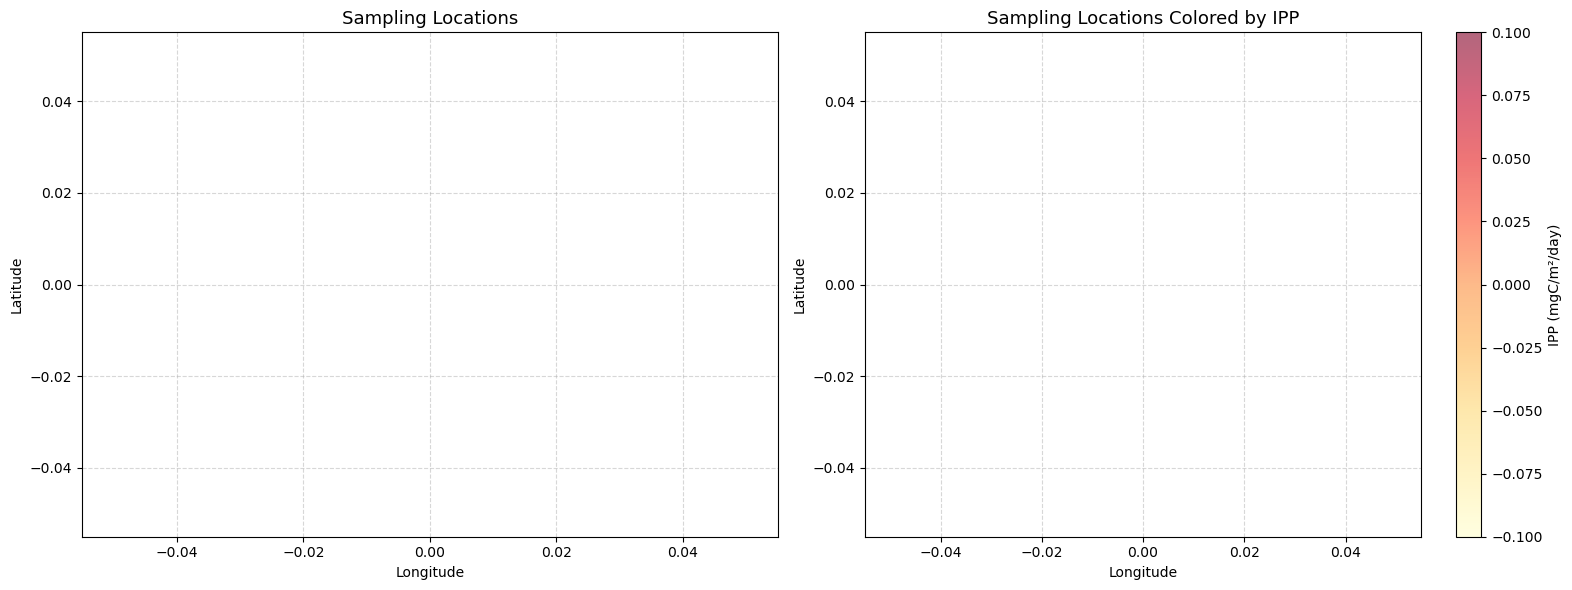

In [9]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# just locations graph 1
axes[0].scatter(
    df4['LONG'], 
    df4['LAT'],
    alpha=0.4, 
    s=10, 
    color='steelblue'
)
axes[0].set_title('Sampling Locations', fontsize=13)
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Color by IPP graph 2
# Only rows where IPP is not NaN
# reddish dots = high productivity areas, yellowish = low
'''
Yellow dot = location has low IPP = less productive ocean
Red dot = location has high IPP = more productive ocean
'''
dfIpp = df4.dropna(subset=['IPP'])

scatter = axes[1].scatter(
    dfIpp['LONG'],
    dfIpp['LAT'],
    c=dfIpp['IPP'],        
    cmap='YlOrRd',    
    alpha=0.6,
    s=15
)
plt.colorbar(scatter, ax=axes[1], label='IPP (mgC/m²/day)')
axes[1].set_title('Sampling Locations Colored by IPP', fontsize=13)
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Dataset 5

In [10]:
import pandas as pd
import numpy as np

def load_behrenfeld_file(filepath, label=None):
    """
    Load a Behrenfeld-Falkowski style .txt file.
    
    filepath : path to the .txt file
    """
    # Read raw lines, skip the $$$ header block
    with open(filepath, 'r') as f:
        lines = f.readlines()
    
    # Find the line where actual column headers start COUNT
    dataStartIdx = None
    for i, line in enumerate(lines):
        if line.strip().startswith('Count'):
            dataStartIdx = i
            break
    
    if dataStartIdx is None:
        raise ValueError(f"Could not find header row in file: {filepath}")
    
    # Parse tab-separated data, starting from the header row
    from io import StringIO
    rawData = ''.join(lines[dataStartIdx:])
    
    df = pd.read_csv(
        StringIO(rawData),
        sep='\t',
        dtype=str       # read everything as string first to handle mixed types
    )
    
    # Clean up column names
    df.columns = df.columns.str.strip()
    
    # Replace empty strings with NaN so ffill works properly
    df.replace('', np.nan, inplace=True)
    
    # Forward-fill the "parent station" columns
    # These are the columns that only appear in the FIRST row of each station
    stationCols = ['Criuse', 'Day', 'Month', 'Year', 'LAT', 'LONG', 
                   'Temp D', 'ayLengh', 'Irr', 'Pb_opt']
    
    for col in stationCols:
        if col in df.columns:
            df[col] = df[col].ffill()
    
    # Drop completely blank rows (the separator rows)
    df.dropna(how='all', inplace=True)
    
    # Drop rows where ALL the important columns are NaN
    df.dropna(subset=['Depth'], inplace=True)
    
    # Convert numeric columns to float
    numericCols = ['Count', 'Day', 'Month', 'Year', 'LAT', 'LONG',
                   'Temp D', 'ayLengh', 'Irr', 'Pb_opt',
                   'Depth', '%Irr', 'O.D.', 'Chl', 'Pb', 'PP', 'IPP']
    
    for col in numericCols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
        
    
    return df


# Dataframe for file 1
df5 = load_behrenfeld_file(
    r"C:\ResearchData\Siegel 5.txt",
    label='dataset_5'
)

print(df5.shape)
print(df5.head(10))
print(df5.dtypes)

(254, 18)
    Count Criuse  Day  Month  Year   LAT  LONG  Temp D  ayLengh    Irr  \
0    2251   BATS   19     12  1988  31.7   NaN     NaN     9.93  20.79   
1    2252   BATS   19     12  1988  31.7   NaN     NaN     9.93  20.79   
2    2253   BATS   19     12  1988  31.7   NaN     NaN     9.93  20.79   
3    2254   BATS   19     12  1988  31.7   NaN     NaN     9.93  20.79   
4    2255   BATS   19     12  1988  31.7   NaN     NaN     9.93  20.79   
5    2256   BATS   19     12  1988  31.7   NaN     NaN     9.93  20.79   
7    2258   BATS   28      1  1989  31.7   NaN     NaN    10.42  25.50   
8    2259   BATS   28      1  1989  31.7   NaN     NaN    10.42  25.50   
9    2260   BATS   28      1  1989  31.7   NaN     NaN    10.42  25.50   
10   2261   BATS   28      1  1989  31.7   NaN     NaN    10.42  25.50   

    Pb_opt  Depth  %Irr  O.D.   Chl    Pb    PP    IPP  
0     6.52    2.1    92  0.08  0.10  6.52  6.15  280.2  
1     6.52   25.0    38  0.96  0.10  5.53  5.35    NaN  
2   

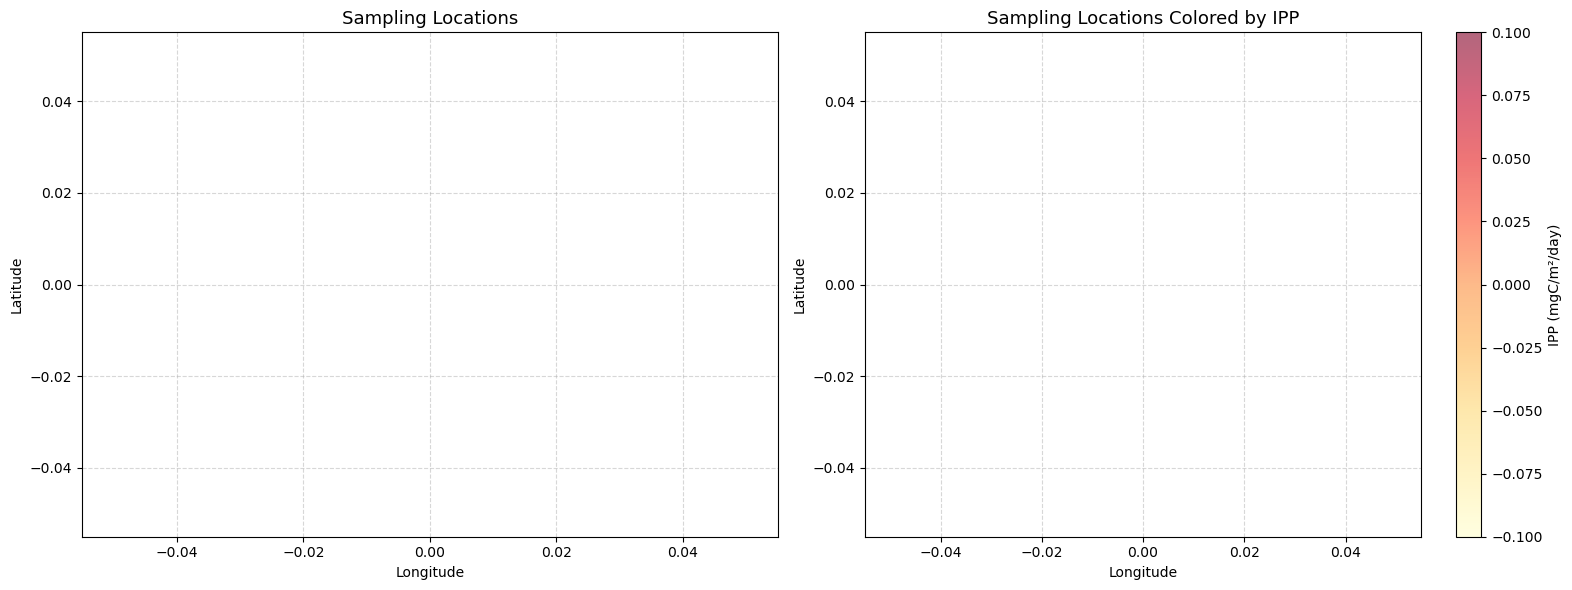

In [11]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# just locations graph 1
axes[0].scatter(
    df5['LONG'], 
    df5['LAT'],
    alpha=0.4, 
    s=10, 
    color='steelblue'
)
axes[0].set_title('Sampling Locations', fontsize=13)
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Color by IPP graph 2
# Only rows where IPP is not NaN
# reddish dots = high productivity areas, yellowish = low
'''
Yellow dot = location has low IPP = less productive ocean
Red dot = location has high IPP = more productive ocean
'''
dfIpp = df5.dropna(subset=['IPP'])

scatter = axes[1].scatter(
    dfIpp['LONG'],
    dfIpp['LAT'],
    c=dfIpp['IPP'],        
    cmap='YlOrRd',    
    alpha=0.6,
    s=15
)
plt.colorbar(scatter, ax=axes[1], label='IPP (mgC/m²/day)')
axes[1].set_title('Sampling Locations Colored by IPP', fontsize=13)
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Dataset 6

In [12]:
import pandas as pd
import numpy as np

def load_behrenfeld_file(filepath, label=None):
    """
    Load a Behrenfeld-Falkowski style .txt file.
    
    filepath : path to the .txt file
    """
    # Read raw lines, skip the $$$ header block
    with open(filepath, 'r') as f:
        lines = f.readlines()
    
    # Find the line where actual column headers start COUNT
    dataStartIdx = None
    for i, line in enumerate(lines):
        if line.strip().startswith('Count'):
            dataStartIdx = i
            break
    
    if dataStartIdx is None:
        raise ValueError(f"Could not find header row in file: {filepath}")
    
    # Parse tab-separated data, starting from the header row
    from io import StringIO
    rawData = ''.join(lines[dataStartIdx:])
    
    df = pd.read_csv(
        StringIO(rawData),
        sep='\t',
        dtype=str       # read everything as string first to handle mixed types
    )
    
    # Clean up column names
    df.columns = df.columns.str.strip()
    
    # Replace empty strings with NaN so ffill works properly
    df.replace('', np.nan, inplace=True)
    
    # Forward-fill the "parent station" columns
    # These are the columns that only appear in the FIRST row of each station
    stationCols = ['Criuse', 'Day', 'Month', 'Year', 'LAT', 'LONG', 
                   'Temp D', 'ayLengh', 'Irr', 'Pb_opt']
    
    for col in stationCols:
        if col in df.columns:
            df[col] = df[col].ffill()
    
    # Drop completely blank rows (the separator rows)
    df.dropna(how='all', inplace=True)
    
    # Drop rows where ALL the important columns are NaN
    df.dropna(subset=['Depth'], inplace=True)
    
    # Convert numeric columns to float
    numericCols = ['Count', 'Day', 'Month', 'Year', 'LAT', 'LONG',
                   'Temp D', 'ayLengh', 'Irr', 'Pb_opt',
                   'Depth', '%Irr', 'O.D.', 'Chl', 'Pb', 'PP', 'IPP']
    
    for col in numericCols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
        
    
    return df


# Dataframe for file 1
df6 = load_behrenfeld_file(
    r"C:\ResearchData\Morel 6.txt",
    label='dataset_6'
)

print(df6.shape)
print(df6.head(10))
print(df6.dtypes)

(1741, 18)
    Count    Criuse  Day  Month    Year    LAT   LONG  Temp D  ayLengh    Irr  \
0    2539  Antiprod    7      3  1977.0 -46.00  66.83     6.0    11.27  23.72   
1    2540  Antiprod    7      3  1977.0 -46.00  66.83     6.0    11.27  23.72   
2    2541  Antiprod    7      3  1977.0 -46.00  66.83     6.0    11.27  23.72   
3    2542  Antiprod    7      3  1977.0 -46.00  66.83     6.0    11.27  23.72   
4    2543  Antiprod    7      3  1977.0 -46.00  66.83     6.0    11.27  23.72   
6    2545  Antiprod   27      3  1977.0 -45.23  66.50     8.8    12.35  19.91   
7    2546  Antiprod   27      3  1977.0 -45.23  66.50     8.8    12.35  19.91   
8    2547  Antiprod   27      3  1977.0 -45.23  66.50     8.8    12.35  19.91   
9    2548  Antiprod   27      3  1977.0 -45.23  66.50     8.8    12.35  19.91   
10   2549  Antiprod   27      3  1977.0 -45.23  66.50     8.8    12.35  19.91   

    Pb_opt  Depth   %Irr  O.D.   Chl    Pb    PP    IPP  
0     3.09    0.0  100.0  0.00  0.15  1

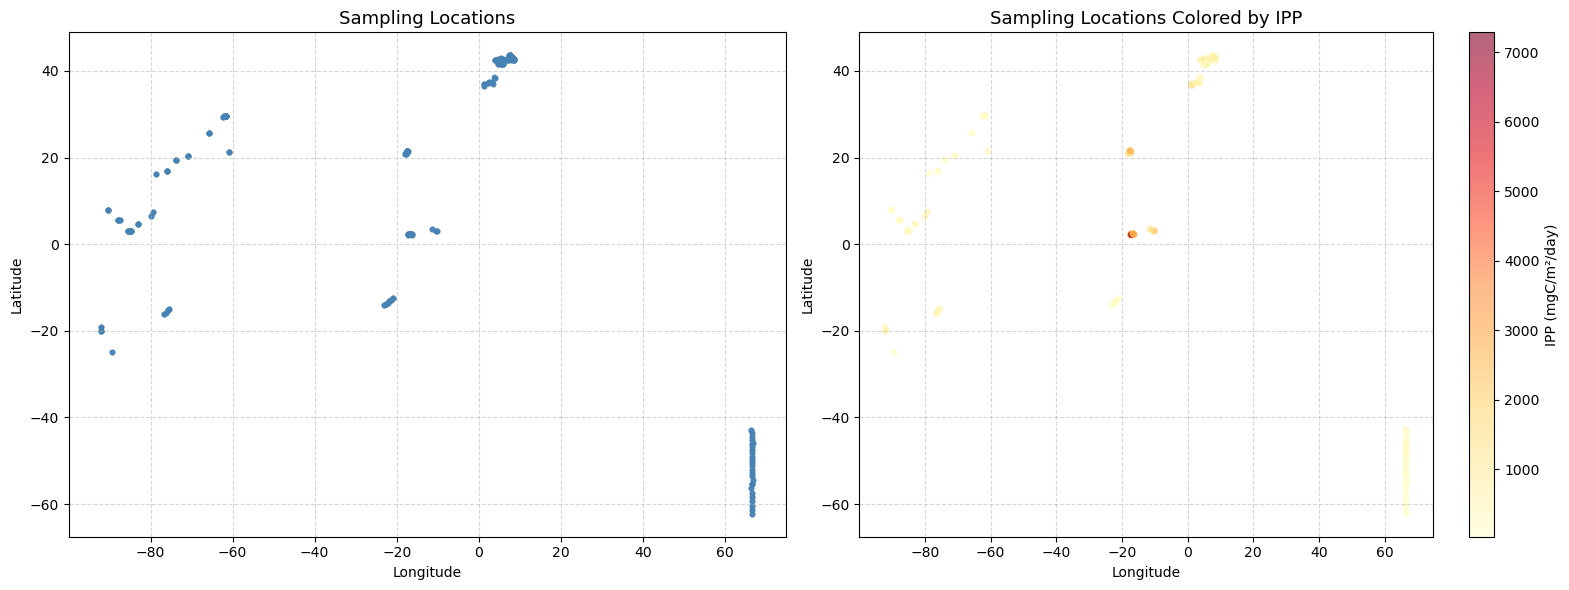

In [13]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# just locations graph 1
axes[0].scatter(
    df6['LONG'], 
    df6['LAT'],
    alpha=0.4, 
    s=10, 
    color='steelblue'
)
axes[0].set_title('Sampling Locations', fontsize=13)
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Color by IPP graph 2
# Only rows where IPP is not NaN
# reddish dots = high productivity areas, yellowish = low
'''
Yellow dot = location has low IPP = less productive ocean
Red dot = location has high IPP = more productive ocean
'''
dfIpp = df6.dropna(subset=['IPP'])

scatter = axes[1].scatter(
    dfIpp['LONG'],
    dfIpp['LAT'],
    c=dfIpp['IPP'],        
    cmap='YlOrRd',    
    alpha=0.6,
    s=15
)
plt.colorbar(scatter, ax=axes[1], label='IPP (mgC/m²/day)')
axes[1].set_title('Sampling Locations Colored by IPP', fontsize=13)
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Dataset 7

In [14]:
import pandas as pd
import numpy as np

def load_behrenfeld_file(filepath, label=None):
    """
    Load a Behrenfeld-Falkowski style .txt file.
    
    filepath : path to the .txt file
    """
    # Read raw lines, skip the $$$ header block
    with open(filepath, 'r') as f:
        lines = f.readlines()
    
    # Find the line where actual column headers start COUNT
    dataStartIdx = None
    for i, line in enumerate(lines):
        if line.strip().startswith('Count'):
            dataStartIdx = i
            break
    
    if dataStartIdx is None:
        raise ValueError(f"Could not find header row in file: {filepath}")
    
    # Parse tab-separated data, starting from the header row
    from io import StringIO
    rawData = ''.join(lines[dataStartIdx:])
    
    df = pd.read_csv(
        StringIO(rawData),
        sep='\t',
        dtype=str       # read everything as string first to handle mixed types
    )
    
    # Clean up column names
    df.columns = df.columns.str.strip()
    
    # Replace empty strings with NaN so ffill works properly
    df.replace('', np.nan, inplace=True)
    
    # Forward-fill the "parent station" columns
    # These are the columns that only appear in the FIRST row of each station
    stationCols = ['Criuse', 'Day', 'Month', 'Year', 'LAT', 'LONG', 
                   'Temp D', 'ayLengh', 'Irr', 'Pb_opt']
    
    for col in stationCols:
        if col in df.columns:
            df[col] = df[col].ffill()
    
    # Drop completely blank rows (the separator rows)
    df.dropna(how='all', inplace=True)
    
    # Drop rows where ALL the important columns are NaN
    df.dropna(subset=['Depth'], inplace=True)
    
    # Convert numeric columns to float
    numericCols = ['Count', 'Day', 'Month', 'Year', 'LAT', 'LONG',
                   'Temp D', 'ayLengh', 'Irr', 'Pb_opt',
                   'Depth', '%Irr', 'O.D.', 'Chl', 'Pb', 'PP', 'IPP']
    
    for col in numericCols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
        
    
    return df


# Dataframe for file 1
df7 = load_behrenfeld_file(
    r"C:\ResearchData\OReilly 7.txt",
    label='dataset_7'
)

print(df7.shape)
print(df7.head(10))
print(df7.dtypes)

(7329, 18)
    Count  Criuse  Day  Month  Year   LAT  LONG  Temp D  ayLengh   Irr  \
0    4589  marmap   16      3  1977  40.2   NaN     NaN    11.81  25.4   
1    4590  marmap   16      3  1977  40.2   NaN     NaN    11.81  25.4   
2    4591  marmap   16      3  1977  40.2   NaN     NaN    11.81  25.4   
3    4592  marmap   16      3  1977  40.2   NaN     NaN    11.81  25.4   
4    4593  marmap   16      3  1977  40.2   NaN     NaN    11.81  25.4   
5    4594  marmap   16      3  1977  40.2   NaN     NaN    11.81  25.4   
6    4595  marmap   16      3  1977  40.2   NaN     NaN    11.81  25.4   
8    4597  marmap   16      3  1977  40.2   NaN     NaN    11.81  25.4   
9    4598  marmap   16      3  1977  40.2   NaN     NaN    11.81  25.4   
10   4599  marmap   16      3  1977  40.2   NaN     NaN    11.81  25.4   

    Pb_opt  Depth  %Irr  O.D.    Chl    Pb      PP     IPP  
0     4.84   0.00   100  0.00  53.89  4.75  3020.0  8017.8  
1     4.84   0.40    69  0.37  53.89  4.84  3080.0  

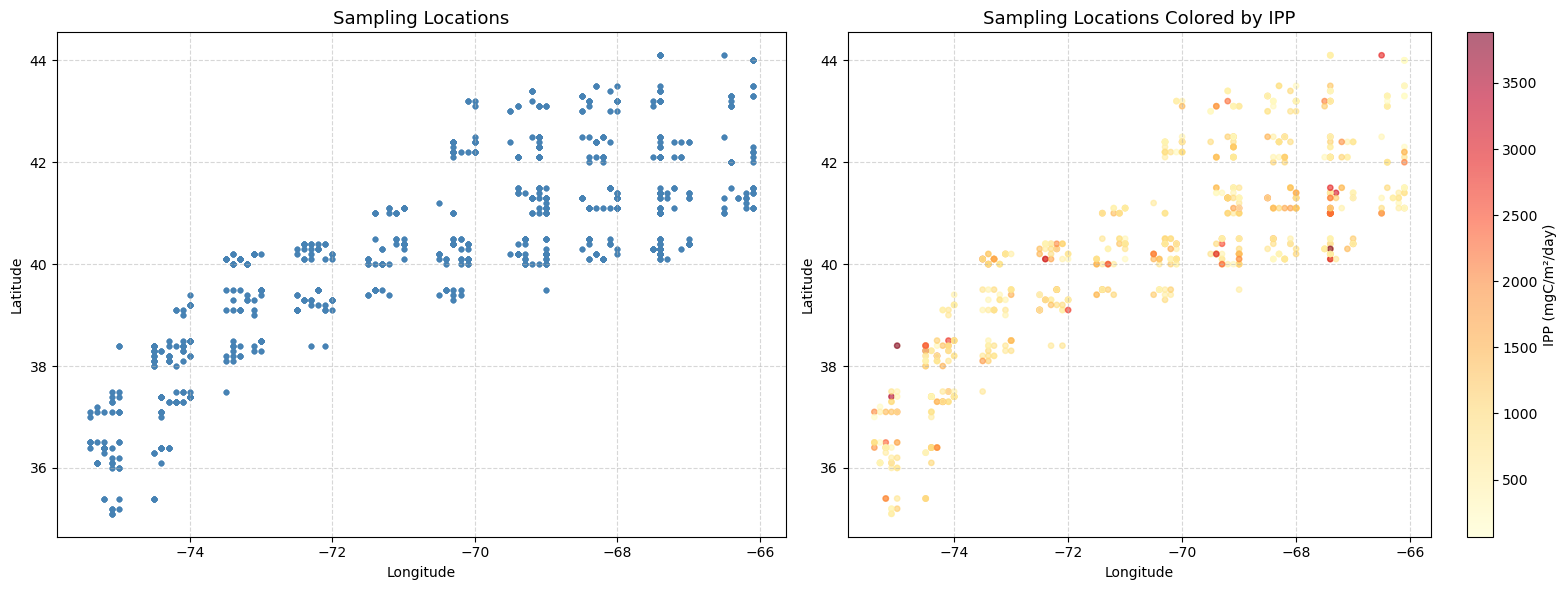

In [15]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# just locations graph 1
axes[0].scatter(
    df7['LONG'], 
    df7['LAT'],
    alpha=0.4, 
    s=10, 
    color='steelblue'
)
axes[0].set_title('Sampling Locations', fontsize=13)
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Color by IPP graph 2
# Only rows where IPP is not NaN
# reddish dots = high productivity areas, yellowish = low
'''
Yellow dot = location has low IPP = less productive ocean
Red dot = location has high IPP = more productive ocean
'''
dfIpp = df7.dropna(subset=['IPP'])

scatter = axes[1].scatter(
    dfIpp['LONG'],
    dfIpp['LAT'],
    c=dfIpp['IPP'],        
    cmap='YlOrRd',    
    alpha=0.6,
    s=15
)
plt.colorbar(scatter, ax=axes[1], label='IPP (mgC/m²/day)')
axes[1].set_title('Sampling Locations Colored by IPP', fontsize=13)
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Dataset 8

In [16]:
import pandas as pd
import numpy as np

def load_behrenfeld_file(filepath, label=None):
    """
    Load a Behrenfeld-Falkowski style .txt file.
    
    filepath : path to the .txt file
    """
    # Read raw lines, skip the $$$ header block
    with open(filepath, 'r') as f:
        lines = f.readlines()
    
    # Find the line where actual column headers start COUNT
    dataStartIdx = None
    for i, line in enumerate(lines):
        if line.strip().startswith('Count'):
            dataStartIdx = i
            break
    
    if dataStartIdx is None:
        raise ValueError(f"Could not find header row in file: {filepath}")
    
    # Parse tab-separated data, starting from the header row
    from io import StringIO
    rawData = ''.join(lines[dataStartIdx:])
    
    df = pd.read_csv(
        StringIO(rawData),
        sep='\t',
        dtype=str       # read everything as string first to handle mixed types
    )
    
    # Clean up column names
    df.columns = df.columns.str.strip()
    
    # Replace empty strings with NaN so ffill works properly
    df.replace('', np.nan, inplace=True)
    
    # Forward-fill the "parent station" columns
    # These are the columns that only appear in the FIRST row of each station
    stationCols = ['Criuse', 'Day', 'Month', 'Year', 'LAT', 'LONG', 
                   'Temp D', 'ayLengh', 'Irr', 'Pb_opt']
    
    for col in stationCols:
        if col in df.columns:
            df[col] = df[col].ffill()
    
    # Drop completely blank rows (the separator rows)
    df.dropna(how='all', inplace=True)
    
    # Drop rows where ALL the important columns are NaN
    df.dropna(subset=['Depth'], inplace=True)
    
    # Convert numeric columns to float
    numericCols = ['Count', 'Day', 'Month', 'Year', 'LAT', 'LONG',
                   'Temp D', 'ayLengh', 'Irr', 'Pb_opt',
                   'Depth', '%Irr', 'O.D.', 'Chl', 'Pb', 'PP', 'IPP']
    
    for col in numericCols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
        
    
    return df


# Dataframe for file 1
df8 = load_behrenfeld_file(
    r"C:\ResearchData\Balch 8.txt",
    label='dataset_8'
)

print(df8.shape)
print(df8.head(10))
print(df8.dtypes)

(9302, 18)
    Count Criuse  Day  Month  Year   LAT  LONG  Temp D  ayLengh    Irr  \
0   12965    bbs   29      5  1958  32.1 -64.3     NaN    13.92  134.0   
1   12966    bbs   29      5  1958  32.1 -64.3     NaN    13.92  134.0   
2   12967    bbs   29      5  1958  32.1 -64.3     NaN    13.92  134.0   
3   12968    bbs   29      5  1958  32.1 -64.3     NaN    13.92  134.0   
4   12969    bbs   29      5  1958  32.1 -64.3     NaN    13.92  134.0   
6   12971    bbs    6      6  1958  32.1 -64.3     NaN    14.02  140.0   
7   12972    bbs    6      6  1958  32.1 -64.3     NaN    14.02  140.0   
8   12973    bbs    6      6  1958  32.1 -64.3     NaN    14.02  140.0   
9   12974    bbs    6      6  1958  32.1 -64.3     NaN    14.02  140.0   
10  12975    bbs    6      6  1958  32.1 -64.3     NaN    14.02  140.0   

    Pb_opt  Depth  %Irr  O.D.   Chl    Pb   PP    IPP  
0     0.99      0   100  0.00  0.05  0.00  0.0   77.4  
1     0.99     14    50  0.69  0.08  0.27  0.3    NaN  
2     

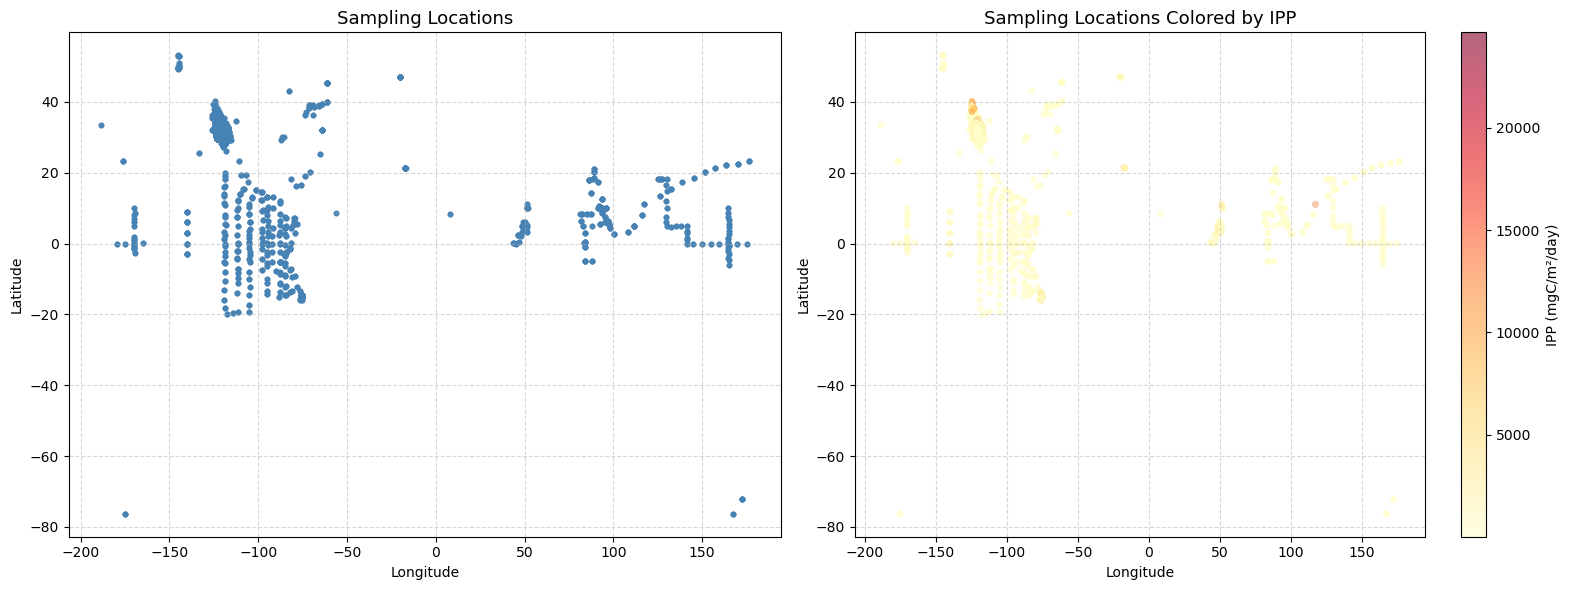

In [17]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# just locations graph 1
axes[0].scatter(
    df8['LONG'], 
    df8['LAT'],
    alpha=0.4, 
    s=10, 
    color='steelblue'
)
axes[0].set_title('Sampling Locations', fontsize=13)
axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Color by IPP graph 2
# Only rows where IPP is not NaN
# reddish dots = high productivity areas, yellowish = low
'''
Yellow dot = location has low IPP = less productive ocean
Red dot = location has high IPP = more productive ocean
'''
dfIpp = df8.dropna(subset=['IPP'])

scatter = axes[1].scatter(
    dfIpp['LONG'],
    dfIpp['LAT'],
    c=dfIpp['IPP'],        
    cmap='YlOrRd',    
    alpha=0.6,
    s=15
)
plt.colorbar(scatter, ax=axes[1], label='IPP (mgC/m²/day)')
axes[1].set_title('Sampling Locations Colored by IPP', fontsize=13)
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Feature Engineering

In [18]:
# to beging our feature engineering we will firstly combine all 8 of these files into one
# master Dataframe by concatinating them all

import pandas as pd
import numpy as np

# Step 1 — Combine all 8 files into one master dataframe
masterDf = pd.concat([df1, df2, df3, df4, df5, df6, df7, df8], ignore_index=True)
print("Master shape:", masterDf.shape)

Master shape: (20558, 18)


In [19]:
# HERE WE ARE CGHECKING THE DATFRAME FOR INVALID DATES

# Check if there are invalid rows
print("Month range:", masterDf['Month'].min(), "to", masterDf['Month'].max())
print("Day range:", masterDf['Day'].min(), "to", masterDf['Day'].max())

# NaN check
print("Month NaNs:", masterDf['Month'].isna().sum())
print("Day NaNs:", masterDf['Day'].isna().sum())

# Problematic rows identify
badRows = masterDf[
    (masterDf['Month'] < 1) | (masterDf['Month'] > 12) |
    (masterDf['Day'] < 1)   | (masterDf['Day'] > 31)   |
    masterDf['Month'].isna() | masterDf['Day'].isna()
]
print("Bad rows:", len(badRows))
print(badRows[['Day', 'Month', 'Year']].head(10))

Month range: 1.0 to 84.0
Day range: 0 to 31
Month NaNs: 6
Day NaNs: 0
Bad rows: 86
       Day  Month    Year
1241     2    NaN  1989.0
1242     2    NaN  1989.0
1243     2    NaN  1989.0
1244     2    NaN  1989.0
1245     2    NaN  1989.0
1246     2    NaN  1989.0
12612   17   84.0  1984.0
12613   17   84.0  1984.0
12614   17   84.0  1984.0
12615   17   84.0  1984.0


In [20]:
# FIXING THE INVALID ROWS
masterDf = masterDf.dropna(subset=['Month', 'Day'])

masterDf = masterDf[
    (masterDf['Month'] >= 1) & (masterDf['Month'] <= 12) &
    (masterDf['Day'] >= 1)   & (masterDf['Day'] <= 31)
]

print("Shape after cleaning:", masterDf.shape)
print("Month range:", masterDf['Month'].min(), "to", masterDf['Month'].max())
print("Day range:", masterDf['Day'].min(), "to", masterDf['Day'].max())


Shape after cleaning: (20472, 18)
Month range: 1.0 to 12.0
Day range: 1 to 31


In [21]:
# this checks and confirms wether the cleaning even occured in the dataset
print("Shape:", masterDf.shape)
print("Month range:", masterDf['Month'].min(), "to", masterDf['Month'].max())
print("Day range:", masterDf['Day'].min(), "to", masterDf['Day'].max())
print("Month NaNs:", masterDf['Month'].isna().sum())
print("Day NaNs:", masterDf['Day'].isna().sum())

Shape: (20472, 18)
Month range: 1.0 to 12.0
Day range: 1 to 31
Month NaNs: 0
Day NaNs: 0


In [22]:
# now we will combine the day + month columns into a single DayOfYear columns and create
#this as a new column in the master dataframe
# errors='coerce' — invalid dates become NaN silently like feb 30th or other dates like that

masterDf['DayOfYear'] = pd.to_datetime(
    dict(year=2001, month=masterDf['Month'], day=masterDf['Day']),
    errors='coerce'
).dt.dayofyear

# Invalid combinations (like Feb 30) dropped
print("Invalid date rows:", masterDf['DayOfYear'].isna().sum())
masterDf = masterDf.dropna(subset=['DayOfYear'])

print("Shape after date cleaning:", masterDf.shape)
print("\nDayOfYear sample:")
print(masterDf[['Day', 'Month', 'DayOfYear']].drop_duplicates().head(10))

Invalid date rows: 26
Shape after date cleaning: (20446, 19)

DayOfYear sample:
    Day  Month  DayOfYear
0    16    3.0       75.0
6    17    3.0       76.0
12   19    3.0       78.0
18   20    3.0       79.0
24   21    3.0       80.0
30   22    3.0       81.0
36   23    3.0       82.0
42   24    3.0       83.0
48   26    3.0       85.0
53   27    3.0       86.0


In [23]:
# Now we will make the Zopt column 
# Join columns (Depth, %Irr) to identify the
# corresponding euphotic layer depth Zopt that satisfies %Irr=1.
'''
What is ZOPT columns understand with a simple analogy.

think of the ocean as a multi floor building where the light from the sun goes from top to
the bottom. So the catch is that as we go down the ocean light gets lesser and lesser similar
to a building. There comes a point where the light is basically 0% but before that 0% there is
a 1% light somewhere a little above that. 


The Zopt column works similalrly it find where the sunlight is 1% per station. We do this by
working with two columns(joining them) depth and irr.
'''
def getZopt(group):
    group = group.sort_values('Depth').dropna(subset=['Depth', '%Irr']) # grouping the values together and dropping the columns where the value of them is NaN
    
    # If %Irr never reaches 1, return NaN
    if group['%Irr'].min() > 1:
        return np.nan
    
    # If %Irr = exactly 1 exists
    exact = group[group['%Irr'] == 1]
    if not exact.empty:
        return exact.iloc[0]['Depth']
    
    # Interpolate between the row just above 1% and just below 1%
    above = group[group['%Irr'] > 1]
    below = group[group['%Irr'] < 1]
    
    if above.empty or below.empty:
        return np.nan
    
    # Take the closest rows on either side
    rowAbove = above.iloc[-1]  # last row still above 1%
    rowBelow = below.iloc[0]   # first row below 1%
    
    # Linear interpolation similar to finding exact point between two floors
    irr1 = rowAbove['%Irr']
    irr2 = rowBelow['%Irr']
    d1   = rowAbove['Depth']
    d2   = rowBelow['Depth']
    
    zopt = d1 + (1 - irr1) * (d2 - d1) / (irr2 - irr1)
    return zopt


# Group by stations where they share same LAT, LONG, Day, Month, Year
stationGroups = masterDf.groupby(['LAT', 'LONG', 'Day', 'Month', 'Year'])
zoptSeries = stationGroups.apply(getZopt).reset_index()
zoptSeries.columns = ['LAT', 'LONG', 'Day', 'Month', 'Year', 'Zopt']

print("Zopt sample:")
print(zoptSeries.head(10))


Zopt sample:
     LAT    LONG  Day  Month    Year   Zopt
0 -76.30 -175.20   19    1.0  1990.0    NaN
1 -76.30  167.30   13    1.0  1990.0    NaN
2 -72.20  172.40   22    1.0  1990.0    NaN
3 -62.23   66.55   17    3.0  1977.0   98.0
4 -61.37   66.50   16    3.0  1977.0  100.0
5 -60.43   66.45   16    3.0  1977.0  100.0
6 -59.38   66.50   15    3.0  1977.0  100.0
7 -58.40   66.52   14    3.0  1977.0   49.0
8 -57.37   66.52   14    3.0  1977.0   49.0
9 -56.32   66.42   13    3.0  1977.0   80.0


In [24]:
# verificatio of the Zopt values 

print("Total stations:", len(zoptSeries))
print("Zopt NaNs:", zoptSeries['Zopt'].isna().sum())
print("Zopt available:", zoptSeries['Zopt'].notna().sum())
print("\nZopt stats:")
print(zoptSeries['Zopt'].describe())

Total stations: 2486
Zopt NaNs: 128
Zopt available: 2358

Zopt stats:
count    2358.000000
mean       51.305882
std        34.665451
min         3.000000
25%        27.000000
50%        41.000000
75%        68.000000
max       282.000000
Name: Zopt, dtype: float64


In [25]:
# Now we will work on the  Chlavg columns 

'''
Chlavg — Average Chlorophyll within the Euphotic Zone (surface to Zopt)

Chlorophyll is a proxy for phytoplankton count — more chlorophyll = more
phytoplankton present at that depth.

We only average chlorophyll values from the surface down to Zopt (the depth
where light = 1%), because below Zopt there is no light and phytoplankton
are inactive — including them would incorrectly drag the average down.

Example:
    Surface (0m)  → Chl = 4.5
    10m deep      → Chl = 3.2
    20m deep      → Chl = 2.1
    Zopt (30m)    → Chl = 1.2
    40m deep      → Chl = 0.1  ← ignored, below Zopt
    
    Chlavg = (4.5 + 3.2 + 2.1 + 1.2) / 4 = 2.75

Why it matters for IPP prediction:
    Zopt tells us how big the productive zone is (factory size).
    Chlavg tells us how many phytoplankton are working in that zone (workers per floor).
    Together they capture the total productive capacity of the water column,
    which directly drives IPP.
'''

def getChlavg(group):
    #We only average the depths within the euphotic zone (depth <= Zopt)

    # group.name = (LAT, LONG, Day, Month, Year) — the groupby key
    lat, long, day, month, year = group.name
    
    # Find Zopt for this station from zoptSeries
    match = zoptSeries[
        (zoptSeries['LAT']   == lat)   & (zoptSeries['LONG']  == long) &
        (zoptSeries['Day']   == day)   & (zoptSeries['Month'] == month) &
        (zoptSeries['Year']  == year)
    ]
    
    if match.empty or pd.isna(match['Zopt'].values[0]):
        return np.nan
    
    zopt = match['Zopt'].values[0]
    
    # Only rows within euphotic zone (depth <= Zopt)
    euphotic = group[group['Depth'] <= zopt].dropna(subset=['Chl'])
    
    if euphotic.empty:
        return np.nan
    
    return euphotic['Chl'].mean()


# group_keys=False — keys ko index mein mat daalo
stationGroups = masterDf.groupby(['LAT', 'LONG', 'Day', 'Month', 'Year'])
chlavgSeries = stationGroups.apply(getChlavg).reset_index()
chlavgSeries.columns = ['LAT', 'LONG', 'Day', 'Month', 'Year', 'Chlavg']

print("Chlavg sample:")
print(chlavgSeries.head(10))
print("\nChlavg NaNs:", chlavgSeries['Chlavg'].isna().sum())
print("Chlavg available:", chlavgSeries['Chlavg'].notna().sum())

Chlavg sample:
     LAT    LONG  Day  Month    Year  Chlavg
0 -76.30 -175.20   19    1.0  1990.0     NaN
1 -76.30  167.30   13    1.0  1990.0     NaN
2 -72.20  172.40   22    1.0  1990.0     NaN
3 -62.23   66.55   17    3.0  1977.0   0.090
4 -61.37   66.50   16    3.0  1977.0   0.084
5 -60.43   66.45   16    3.0  1977.0   0.100
6 -59.38   66.50   15    3.0  1977.0   0.132
7 -58.40   66.52   14    3.0  1977.0   0.150
8 -57.37   66.52   14    3.0  1977.0   0.496
9 -56.32   66.42   13    3.0  1977.0   0.108

Chlavg NaNs: 128
Chlavg available: 2358


In [26]:
# ALL THE FEATURE ENGINEERING IS DONE NOW AND WE WILL NOW MAKE A FINAL DATAFRAME 
# WITH EVERYTHING AS BEFORE BUT TWO NEW COLUMNS WILL BE ADDED, THE CHLAVG & ZOPT
#THE OTHER FEATURES WE USE AS IS SO WE WILL MAKE A DATAFRAME BASICALLY WITH ALL THE FEATURES 
#WE  WILL TRIN WITH AND THE IPP VALUIES AS WELL WHICH WE ARE TRYIONG TO PREDICT


# Final model dataframe ready
# IPP is always on the surface row of each station, we will extract that value
ippPerStation = masterDf.dropna(subset=['IPP']).groupby(
    ['LAT', 'LONG', 'Day', 'Month', 'Year']
).agg(
    Temp      = ('Temp D',    'first'),
    DayLength = ('ayLengh',   'first'),
    Irr       = ('Irr',       'first'),
    IPP       = ('IPP',       'first'),
    DayOfYear = ('DayOfYear', 'first')
).reset_index()

# Zopt and Chlavg merged
modelDf = ippPerStation.merge(zoptSeries,  on=['LAT','LONG','Day','Month','Year'], how='left')
modelDf = modelDf.merge(chlavgSeries, on=['LAT','LONG','Day','Month','Year'], how='left')

# only 6 features + target variable in the final DF
finalDf = modelDf[['DayOfYear', 'Temp', 'DayLength', 'Irr', 'Zopt', 'Chlavg', 'IPP']].copy()

# drop any NaN value row
finalDf.dropna(inplace=True)
finalDf = finalDf.reset_index(drop=True)

print("Final model-ready shape:", finalDf.shape)
print("\nSample:")
print(finalDf.head(10))
print("\nStats:")
print(finalDf.describe())
print("\nList of Columns:")
print(finalDf.columns)

Final model-ready shape: (1244, 7)

Sample:
   DayOfYear  Temp  DayLength    Irr   Zopt  Chlavg    IPP
0       76.0   1.7      11.67  12.97   98.0   0.090   30.0
1       75.0   1.9      11.58  22.99  100.0   0.084   49.3
2       75.0   2.5      11.60  22.99  100.0   0.100   63.1
3       74.0   2.6      11.53   5.00  100.0   0.132  140.7
4       73.0   2.4      11.46  12.59   49.0   0.150   67.2
5       73.0   3.3      11.48  12.59   49.0   0.496  168.8
6       72.0   2.8      11.42   7.10   80.0   0.108   64.3
7       79.0   3.6      11.98  20.34   80.0   0.124   67.5
8       72.0   3.9      11.44   7.10   80.0   0.220   92.1
9       71.0   3.7      11.39  18.63   90.0   0.088   93.7

Stats:
         DayOfYear         Temp    DayLength          Irr         Zopt  \
count  1244.000000  1244.000000  1244.000000  1244.000000  1244.000000   
mean    182.102090    12.945273    12.541455    30.063609    34.857934   
std      95.517484     6.277577     2.533814    16.640406    18.903655   
min

## Feature Engineering — Final Dataset Summary

The original master dataframe contained **20,558 rows** across all 8 datasets.
After feature engineering, the final model-ready dataframe contains **1,244 rows**.

This reduction is expected and correct for the following reasons:

- **IPP is recorded only once per station** (at the surface row) — all sub-surface
  depth rows do not carry an IPP value, so only one row per station survives
- **Temperature (Temp) was missing** for several stations, particularly in older
  datasets (e.g. bbs cruise from 1958), causing those stations to be dropped
- **Zopt and Chlavg could not be computed** for 128 stations where light never
  reached 1% (primarily Antarctic/Arctic regions in winter)

Each of the **1,244 remaining rows represents one unique sampling station**,
with one IPP value and all six features fully available. This is the correct
unit of observation for model training.

# Now we will do a EDA

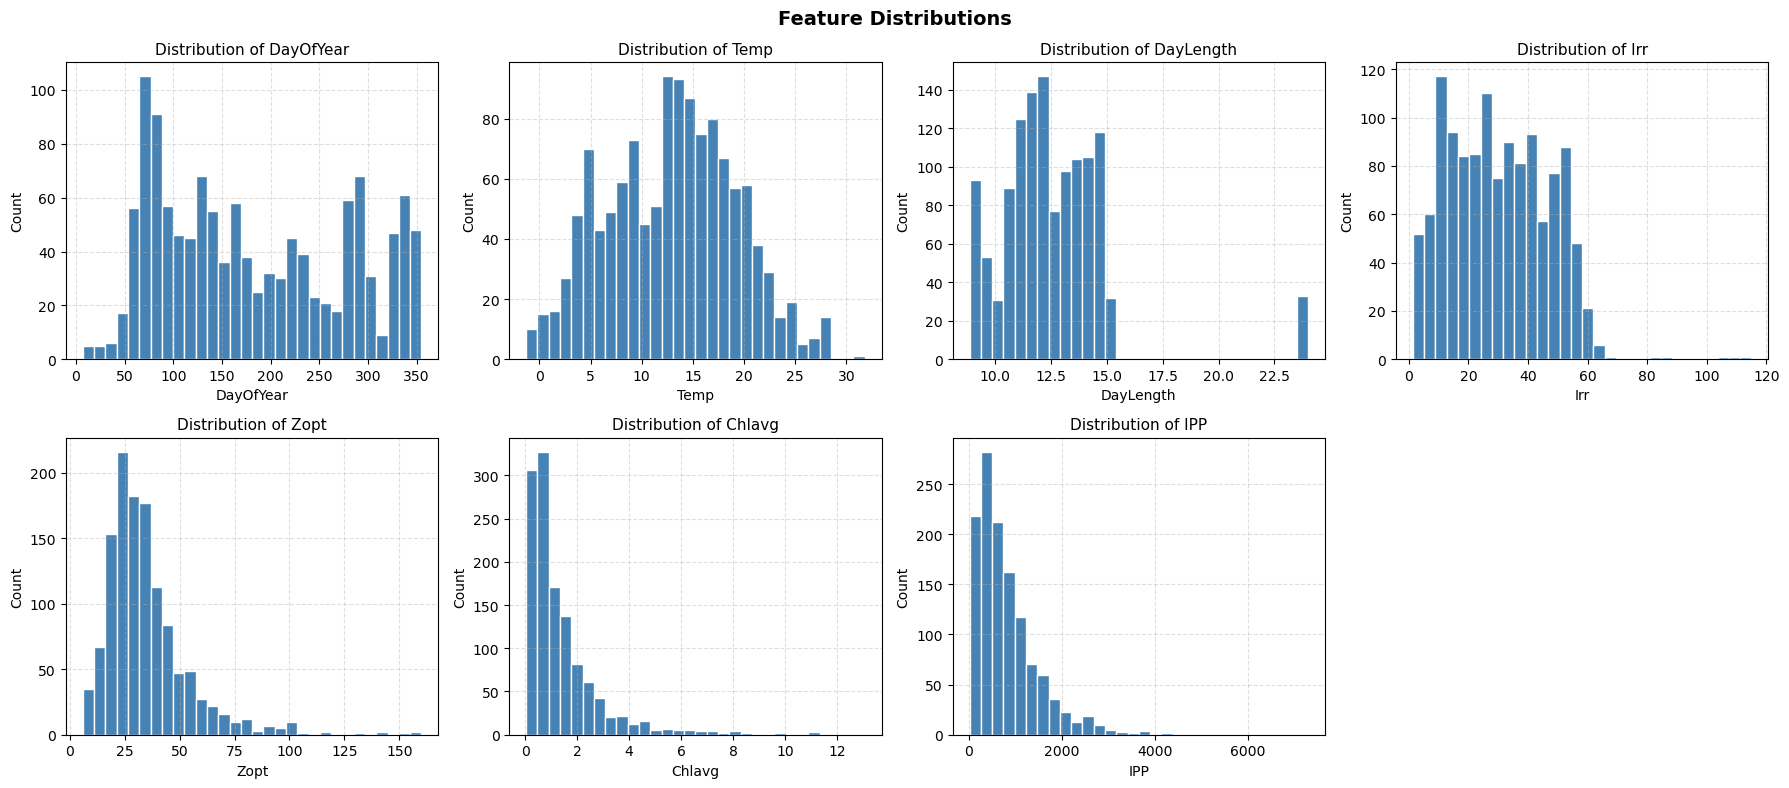

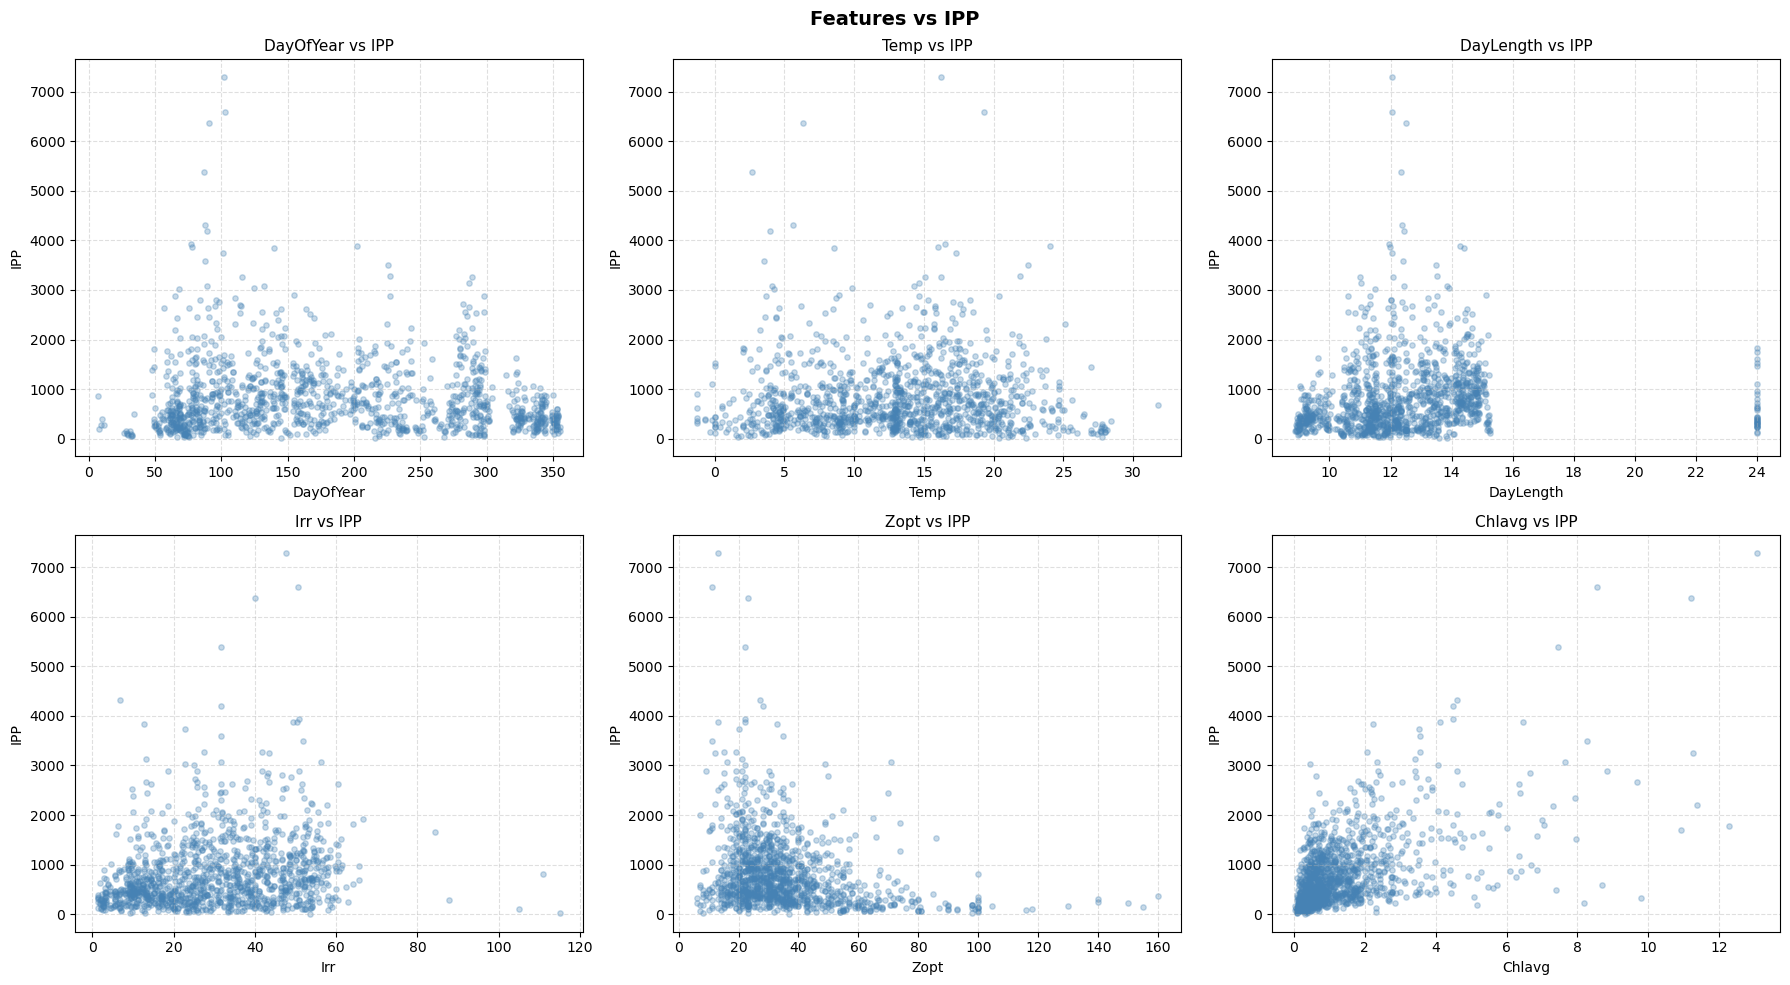

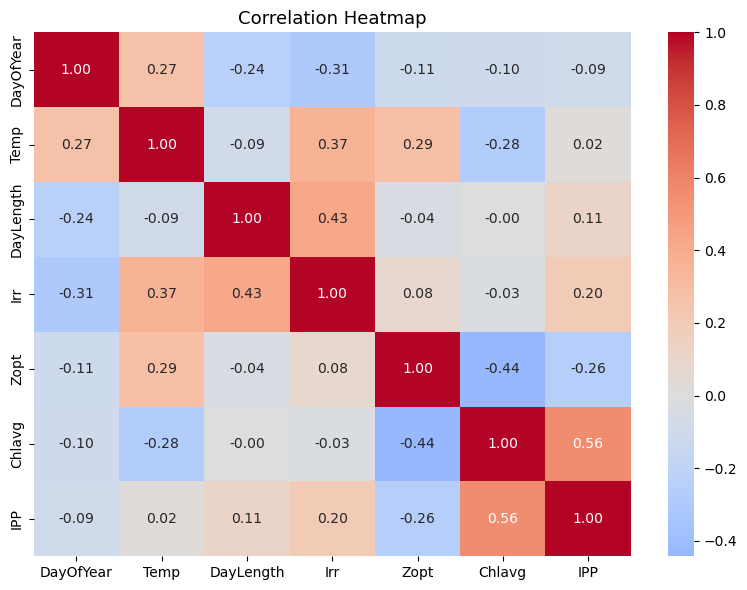

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

features = ['DayOfYear', 'Temp', 'DayLength', 'Irr', 'Zopt', 'Chlavg']

# graph 1 is the Distribution of each feature + IPP 
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(features + ['IPP']):
    axes[i].hist(finalDf[col], bins=30, color='steelblue', edgecolor='white')
    axes[i].set_title(f'Distribution of {col}', fontsize=11)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')
    axes[i].grid(True, linestyle='--', alpha=0.4)

axes[7].set_visible(False)  
plt.suptitle('Feature Distributions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


# Graph 2 is representing Each feature vs IPP scatter
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    axes[i].scatter(finalDf[col], finalDf['IPP'],
                    alpha=0.3, s=15, color='steelblue')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('IPP')
    axes[i].set_title(f'{col} vs IPP', fontsize=11)
    axes[i].grid(True, linestyle='--', alpha=0.4)

plt.suptitle('Features vs IPP', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


# Graph 3 is the Correlation Heatmap
fig, ax = plt.subplots(figsize=(8, 6))

corrMatrix = finalDf.corr()
sns.heatmap(
    corrMatrix,
    annot=True,          
    fmt='.2f',           # rounf to 2 decimal places
    cmap='coolwarm',     # blue = negative, red = positive correlation
    center=0,
    ax=ax
)
ax.set_title('Correlation Heatmap', fontsize=13)
plt.tight_layout()
plt.show()

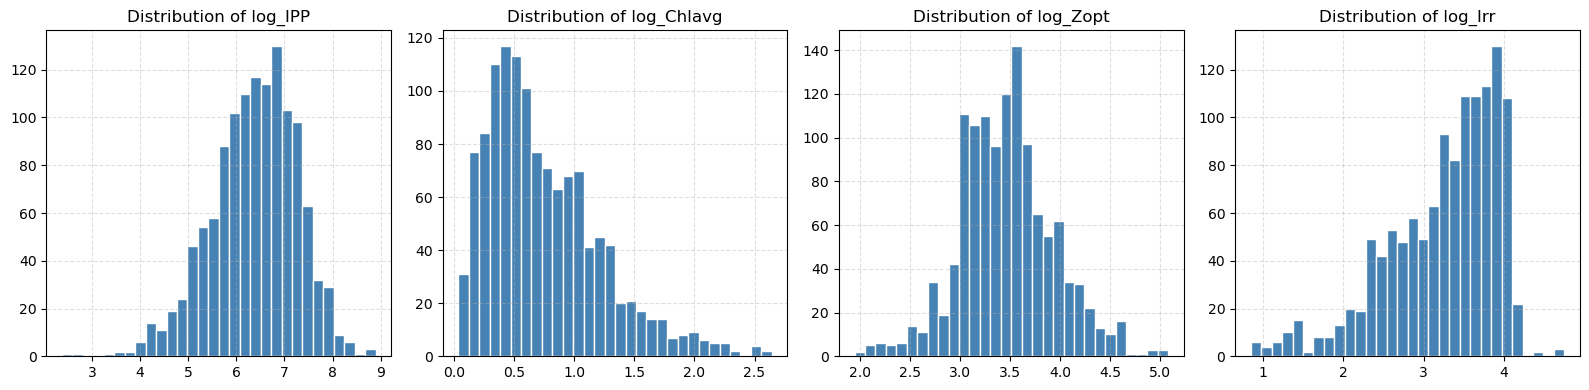

In [28]:
# since there is a lot of skewness in the graphs above so we will apply log transformation

# Log transform applied on the skewed features
import numpy as np

finalDf['log_IPP']    = np.log1p(finalDf['IPP'])
finalDf['log_Chlavg'] = np.log1p(finalDf['Chlavg'])
finalDf['log_Zopt']   = np.log1p(finalDf['Zopt'])
finalDf['log_Irr']    = np.log1p(finalDf['Irr'])

# check if the distribution got better or not
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i, col in enumerate(['log_IPP', 'log_Chlavg', 'log_Zopt', 'log_Irr']):
    axes[i].hist(finalDf[col], bins=30, color='steelblue', edgecolor='white')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# Now we will split the data into training and testing but also apply standard scalerisation as well

In [29]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Features and target
X = finalDf[['DayOfYear', 'Temp', 'DayLength', 'log_Irr', 'log_Zopt', 'log_Chlavg']] #training features
y = finalDf['log_IPP'] # target variable

# Train/Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Applying standard scalr but only on training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # fit + transform
X_test_scaled  = scaler.transform(X_test)        # sirf transform ← cheating nahi!

print("Train size:", X_train_scaled.shape)
print("Test size:", X_test_scaled.shape)

Train size: (995, 6)
Test size: (249, 6)


# Model training

In [30]:
import numpy as np
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
from xgboost import XGBRegressor

# ============================================================
# Model 1 — Linear Regression (Baseline)
# ============================================================
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)
r2_lr     = r2_score(y_test, y_pred_lr)
rmse_lr   = np.sqrt(mean_squared_error(y_test, y_pred_lr))

print("=== Linear Regression ===")
print(f"R² Score : {r2_lr:.4f}")
print(f"RMSE     : {rmse_lr:.4f}")


# ============================================================
# Model 2 — Random Forest
# ============================================================
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
rf.fit(X_train_scaled, y_train)

y_pred_rf = rf.predict(X_test_scaled)
r2_rf     = r2_score(y_test, y_pred_rf)
rmse_rf   = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print("\n=== Random Forest ===")
print(f"R² Score : {r2_rf:.4f}")
print(f"RMSE     : {rmse_rf:.4f}")


# ============================================================
# Model 3 — XGBoost
# ============================================================
xgb = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    random_state=42,
    verbosity=0           
)
xgb.fit(X_train_scaled, y_train)

y_pred_xgb = xgb.predict(X_test_scaled)
r2_xgb     = r2_score(y_test, y_pred_xgb)
rmse_xgb   = np.sqrt(mean_squared_error(y_test, y_pred_xgb))

print("\n=== XGBoost ===")
print(f"R² Score : {r2_xgb:.4f}")
print(f"RMSE     : {rmse_xgb:.4f}")


# ============================================================
# Model 4 — MLP Neural Network (Multilayered)
# ============================================================
mlp = MLPRegressor(
    hidden_layer_sizes=(64, 32, 16),
    activation='relu',
    max_iter=500,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1
)
mlp.fit(X_train_scaled, y_train)

y_pred_mlp = mlp.predict(X_test_scaled)
r2_mlp     = r2_score(y_test, y_pred_mlp)
rmse_mlp   = np.sqrt(mean_squared_error(y_test, y_pred_mlp))

print("\n=== MLP Neural Network ===")
print(f"R² Score : {r2_mlp:.4f}")
print(f"RMSE     : {rmse_mlp:.4f}")


# ============================================================
# Final Comparison Table
# ============================================================
print("\n============= MODEL COMPARISON =============")
print(f"{'Model':<25} {'R²':>8} {'RMSE':>8}")
print("-" * 45)
print(f"{'Linear Regression':<25} {r2_lr:>8.4f} {rmse_lr:>8.4f}")
print(f"{'Random Forest':<25} {r2_rf:>8.4f} {rmse_rf:>8.4f}")
print(f"{'XGBoost':<25} {r2_xgb:>8.4f} {rmse_xgb:>8.4f}")
print(f"{'MLP Neural Network':<25} {r2_mlp:>8.4f} {rmse_mlp:>8.4f}")

# Best model
scores = {
    'Linear Regression': r2_lr,
    'Random Forest':     r2_rf,
    'XGBoost':           r2_xgb,
    'MLP Neural Network': r2_mlp
}
best = max(scores, key=scores.get)
print(f"\nBest Model: {best} (R² = {scores[best]:.4f})")

=== Linear Regression ===
R² Score : 0.3593
RMSE     : 0.7184

=== Random Forest ===
R² Score : 0.5927
RMSE     : 0.5727

=== XGBoost ===
R² Score : 0.6092
RMSE     : 0.5611

=== MLP Neural Network ===
R² Score : 0.4708
RMSE     : 0.6528

============= MODEL COMPARISON =============
Model                           R²     RMSE
---------------------------------------------
Linear Regression           0.3593   0.7184
Random Forest               0.5927   0.5727
XGBoost                     0.6092   0.5611
MLP Neural Network          0.4708   0.6528

Best Model: XGBoost (R² = 0.6092)


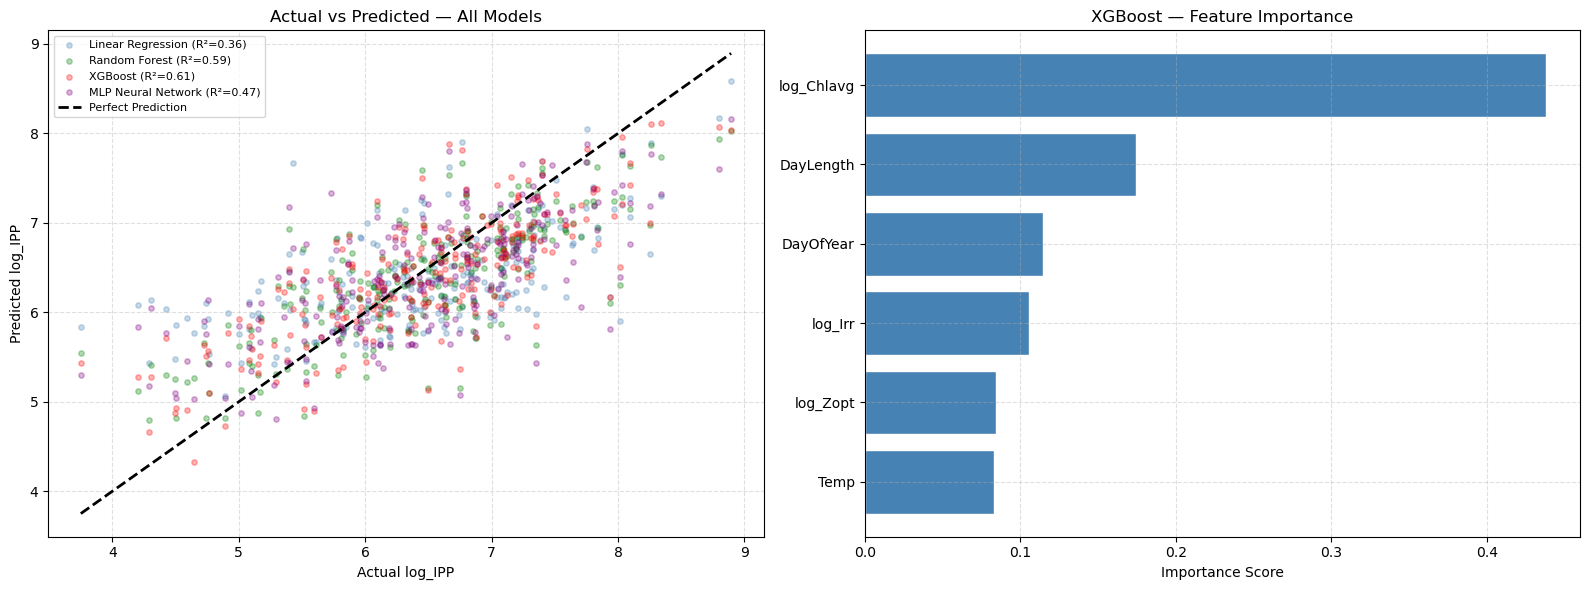

In [31]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

#Graph  1: Actual vs Predicted for All 4 Models
models = {
    'Linear Regression': y_pred_lr,
    'Random Forest':     y_pred_rf,
    'XGBoost':           y_pred_xgb,
    'MLP Neural Network': y_pred_mlp
}

colors = ['steelblue', 'green', 'red', 'purple']

for (name, preds), color in zip(models.items(), colors):
    axes[0].scatter(y_test, preds, alpha=0.3, s=15, 
                    label=f'{name} (R²={r2_score(y_test, preds):.2f})',
                    color=color)

# Perfect prediction line
axes[0].plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()],
             'k--', linewidth=2, label='Perfect Prediction')
axes[0].set_xlabel('Actual log_IPP')
axes[0].set_ylabel('Predicted log_IPP')
axes[0].set_title('Actual vs Predicted — All Models')
axes[0].legend(fontsize=8)
axes[0].grid(True, linestyle='--', alpha=0.4)


# Graph 2: XGBoost Feature Importance
features = ['DayOfYear', 'Temp', 'DayLength', 'log_Irr', 'log_Zopt', 'log_Chlavg']
importance = xgb.feature_importances_

# Sort by importance
sortedIdx = importance.argsort()
axes[1].barh([features[i] for i in sortedIdx],
              importance[sortedIdx],
              color='steelblue', edgecolor='white')
axes[1].set_title('XGBoost — Feature Importance')
axes[1].set_xlabel('Importance Score')
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# from the above training we saw that the model that performed the best was Xgboost.

## We will now do hyperparameter tuning of this Xgobbost model to attain a better R^2 and RMSE score

In [32]:
# we will be adjusting 4 parameters of Xgboost listed below 
#Since we are doing this on CPU we will do randomizedsearchCV which cheks random combinations rather than 
# Grid search which goes through everypossible combination but takes up alot of computing power
from sklearn.model_selection import RandomizedSearchCV
import numpy as np
from xgboost import XGBRegressor

'''
Hyperparameter Tuning means Finding the Best Settings for XGBoost

Think of XGBoost like a tandoor:
- n_estimators  = how many rounds of cooking (more = better but slower)
- max_depth      = how detailed each tree is (too deep = overfit)
- learning_rate  = how big each learning step is (small = careful, large = fast)
- subsample      = what fraction of data each tree sees (prevents overfit)
- colsample_bytree = what fraction of features each tree uses

We use RandomizedSearchCV — tries random combinations and finds the best one.
'''

# Define the search space
# basically we are defining the domain in which we can make multiple many combinations to see what works best for us
paramGrid = {
    'n_estimators'    : [100, 200, 300, 500],
    'max_depth'       : [3, 4, 5, 6, 7],
    'learning_rate'   : [0.01, 0.05, 0.1, 0.2],
    'subsample'       : [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'min_child_weight' : [1, 3, 5],      
    'gamma'            : [0, 0.1, 0.2]
}

# Base model, this the model with deault settings
xgbBase = XGBRegressor(random_state=42, verbosity=0)

# RandomizedSearchCV setup to try every combination from abve 
randomSearch = RandomizedSearchCV(
    estimator  = xgbBase,
    param_distributions = paramGrid,
    n_iter     = 150,        # 80 random combinations will be tried
    cv         = 5,         # 5-fold cross validation will occur.
    scoring    = 'r2',      # R^2 maximize we have to
    random_state = 42,
    n_jobs     = -1,        # use all the cores in the CPU to be quicker
    verbose    = 1          # show progress
)
'''
The five fold cross validations in this case specifically is that we will split the data into 
5 different parts and train our model on say sets 1,2,3, and 4, then we will test on the 5 set.
We will try different combinations as well like 2,4,1, and 5 to train and test on 3. 
'''

# Run the search
print("Tuning in progress")
randomSearch.fit(X_train_scaled, y_train)

# Best settings
print("\n Best Parameters:")
print(randomSearch.best_params_)
print(f"\nBest CV R^2: {randomSearch.best_score_:.4f}")

# Final model with best settings
xgbTuned = randomSearch.best_estimator_

y_pred_tuned = xgbTuned.predict(X_test_scaled)
r2_tuned     = r2_score(y_test, y_pred_tuned)
rmse_tuned   = np.sqrt(mean_squared_error(y_test, y_pred_tuned))

print("\nTUNING RESULTS:")
print("\n")
print(f"{'Model':<30} {'R^2':>8} {'RMSE':>8}")
print(f"{'XGBoost (Default)':<30} {r2_xgb:>8.4f} {rmse_xgb:>8.4f}")
print(f"{'XGBoost (Tuned)':<30} {r2_tuned:>8.4f} {rmse_tuned:>8.4f}")

improvement = r2_tuned - r2_xgb
print(f"\nR² Improvement: +{improvement:.4f}")

Tuning in progress
Fitting 5 folds for each of 150 candidates, totalling 750 fits

 Best Parameters:
{'subsample': 0.7, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.05, 'gamma': 0.1, 'colsample_bytree': 0.7}

Best CV R^2: 0.5802

TUNING RESULTS:


Model                               R^2     RMSE
XGBoost (Default)                0.6092   0.5611
XGBoost (Tuned)                  0.6455   0.5344

R² Improvement: +0.0363


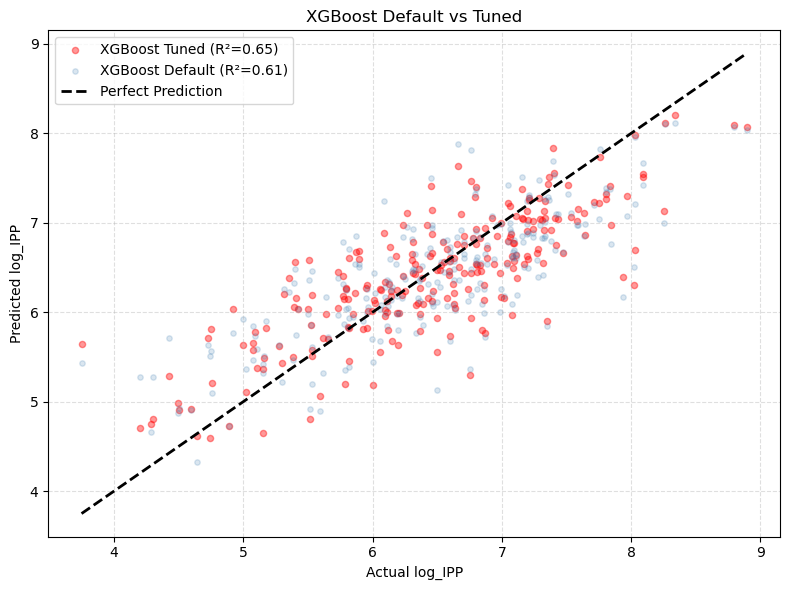

In [33]:
# Now we will graph what we have done, Actual vs. Predicted


fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(y_test, y_pred_tuned, 
           alpha=0.4, s=20, 
           color='red', 
           label=f'XGBoost Tuned (R²={r2_tuned:.2f})')

ax.scatter(y_test, y_pred_xgb,
           alpha=0.2, s=15,
           color='steelblue',
           label=f'XGBoost Default (R²={r2_xgb:.2f})')

# Perfect prediction line
ax.plot([y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        'k--', linewidth=2, label='Perfect Prediction')

ax.set_xlabel('Actual log_IPP')
ax.set_ylabel('Predicted log_IPP')
ax.set_title('XGBoost Default vs Tuned')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# Now we will explore of a Deep Learning approach

In [34]:
import torch
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.10.0
GPU available: False


In [35]:
print(finalDf.shape)
print(finalDf.columns.tolist())
print(X_train_scaled.shape)

(1244, 11)
['DayOfYear', 'Temp', 'DayLength', 'Irr', 'Zopt', 'Chlavg', 'IPP', 'log_IPP', 'log_Chlavg', 'log_Zopt', 'log_Irr']
(995, 6)


In [ ]:
# firstly we will import all the packages we will use in this deep learnig part

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error

In [38]:
# now we will convert data to tensors

# Convert numpy arrays to PyTorch Tensors
# Tensors = PyTorch ka apna data format — numpy arrays jaisa hi
X_train_tensor = torch.FloatTensor(X_train_scaled)
X_test_tensor  = torch.FloatTensor(X_test_scaled)
y_train_tensor = torch.FloatTensor(y_train.values).reshape(-1, 1)
y_test_tensor  = torch.FloatTensor(y_test.values).reshape(-1, 1)

# DataLoader — data ko chhote chhote batches mein feed karta hai
# batch_size=32 matlab ek baar mein 32 rows model ko dikhao
# shuffle=True matlab har epoch mein data ka order random karo
trainDataset = TensorDataset(X_train_tensor, y_train_tensor)
trainLoader  = DataLoader(trainDataset, batch_size=32, shuffle=True)

print("Train tensor shape:", X_train_tensor.shape)
print("Test tensor shape :", X_test_tensor.shape)

Train tensor shape: torch.Size([995, 6])
Test tensor shape : torch.Size([249, 6])


# Model #1

In [39]:
# Simple Deep Neural Network
# This is the very basic deep learning: Input -> Hidden Layers -> Output

class SimpleDNN(nn.Module):
    def __init__(self):
        super(SimpleDNN, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(6, 64),    # 6 features -> 64 neurons think of this like the diagrams
            nn.ReLU(), # This is the activation function Relu
            nn.Linear(64, 32),   # 64 -> 32 neurons
            nn.ReLU(),
            nn.Linear(32, 16),   # 32 -> 16 neurons
            nn.ReLU(),
            nn.Linear(16, 1)     # 16 -> 1 output (log_IPP)
        )

    def forward(self, x):
        return self.network(x)

print("Simple DNN architecture:")
print(SimpleDNN())

Simple DNN architecture:
SimpleDNN(
  (network): Sequential(
    (0): Linear(in_features=6, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=1, bias=True)
  )
)


# Model #2

In [40]:
# Improved DNN with Dropout + Batch Normalization
# Batch Normalization = har layer ka output normalize karo
#                       (sab neurons same scale pe)
# Dropout = training mein random neurons band karo
#           (prevents overfitting — model zyada generalize karta hai)

class ImprovedDNN(nn.Module):
    def __init__(self):
        super(ImprovedDNN, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(6, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),       # 30% neurons randomly off

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),       # 20% neurons randomly off

            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.1),       # 10% neurons randomly off

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)

print("Improved DNN architecture:")
print(ImprovedDNN())

Improved DNN architecture:
ImprovedDNN(
  (network): Sequential(
    (0): Linear(in_features=6, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.1, inplace=False)
    (12): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [43]:
# TRAINING FUNCTION

# Training function — same for both models
# Epochs = kitni baar poora data dekhe model
# lr = learning rate — har step mein kitna seekhe
# Loss = kitni galti hui — isko minimize karna hai

def trainModel(model, trainLoader, epochs=200, lr=0.001):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, patience=20, factor=0.5
    )  # learning rate automatically kam karo agar improvement ruk jaaye

    trainLosses = []

    for epoch in range(epochs):
        model.train()
        epochLoss = 0

        for xBatch, yBatch in trainLoader:
            optimizer.zero_grad()                    # gradients reset
            predictions = model(xBatch)              # forward pass
            loss = criterion(predictions, yBatch)    # loss calculate
            loss.backward()                          # backward pass
            optimizer.step()                         # weights update
            epochLoss += loss.item()

        avgLoss = epochLoss / len(trainLoader)
        trainLosses.append(avgLoss)
        scheduler.step(avgLoss)

        if (epoch + 1) % 50 == 0:
            print(f"Epoch {epoch+1}/{epochs} — Loss: {avgLoss:.4f}")

    return trainLosses

print("Training function ready.")

Training function ready.


In [73]:
# Now we will Traing both of the models 


torch.manual_seed(42)
np.random.seed(42)

# Train Model 1 — Simple DNN
print("Training Model 1 — Simple DNN: ")
model1  = SimpleDNN()
losses1 = trainModel(model1, trainLoader, epochs=300, lr=0.001)

# Train Model 2 — Improved DNN
print("Training Model 2 — Improved DNN (Dropout + BatchNorm): ")
model2  = ImprovedDNN()
losses2 = trainModel(model2, trainLoader, epochs=500, lr=0.001)

print("\nBoth models trained.")

Training Model 1 — Simple DNN: 
Epoch 50/300 — Loss: 0.3358
Epoch 100/300 — Loss: 0.3037
Epoch 150/300 — Loss: 0.2880
Epoch 200/300 — Loss: 0.2595
Epoch 250/300 — Loss: 0.2661
Epoch 300/300 — Loss: 0.2378
Training Model 2 — Improved DNN (Dropout + BatchNorm): 
Epoch 50/500 — Loss: 0.7120
Epoch 100/500 — Loss: 0.7518
Epoch 150/500 — Loss: 0.5894
Epoch 200/500 — Loss: 0.6400
Epoch 250/500 — Loss: 0.6286
Epoch 300/500 — Loss: 0.5430
Epoch 350/500 — Loss: 0.5883
Epoch 400/500 — Loss: 0.5125
Epoch 450/500 — Loss: 0.5571
Epoch 500/500 — Loss: 0.5067

Both models trained.


In [75]:
# Evaluate models on test data
# model.eval() = dropout off ho jaata hai evaluation mein
# torch.no_grad() = gradients calculate mat karo — faster!

def evaluateModel(model, X_test_tensor, y_test):
    model.eval()
    with torch.no_grad():
        predictions = model(X_test_tensor).numpy().flatten()
    r2   = r2_score(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    return predictions, r2, rmse

pred1, r2_dnn1, rmse_dnn1 = evaluateModel(model1, X_test_tensor, y_test)
pred2, r2_dnn2, rmse_dnn2 = evaluateModel(model2, X_test_tensor, y_test)

print("DEEP LEARNING RESULTS: ")
print(f"{'Model':<35} {'R²':>8} {'RMSE':>8}")
print(f"{'Simple DNN':<35} {r2_dnn1:>8.4f} {rmse_dnn1:>8.4f}")
print(f"{'Improved DNN (Dropout+BatchNorm)':<35} {r2_dnn2:>8.4f} {rmse_dnn2:>8.4f}")
print(f"{'XGBoost Tuned':<35} {r2_tuned:>8.4f} {rmse_tuned:>8.4f}")

DEEP LEARNING RESULTS: 
Model                                     R²     RMSE
Simple DNN                            0.5166   0.6240
Improved DNN (Dropout+BatchNorm)      0.5035   0.6323
XGBoost Tuned                         0.6455   0.5344


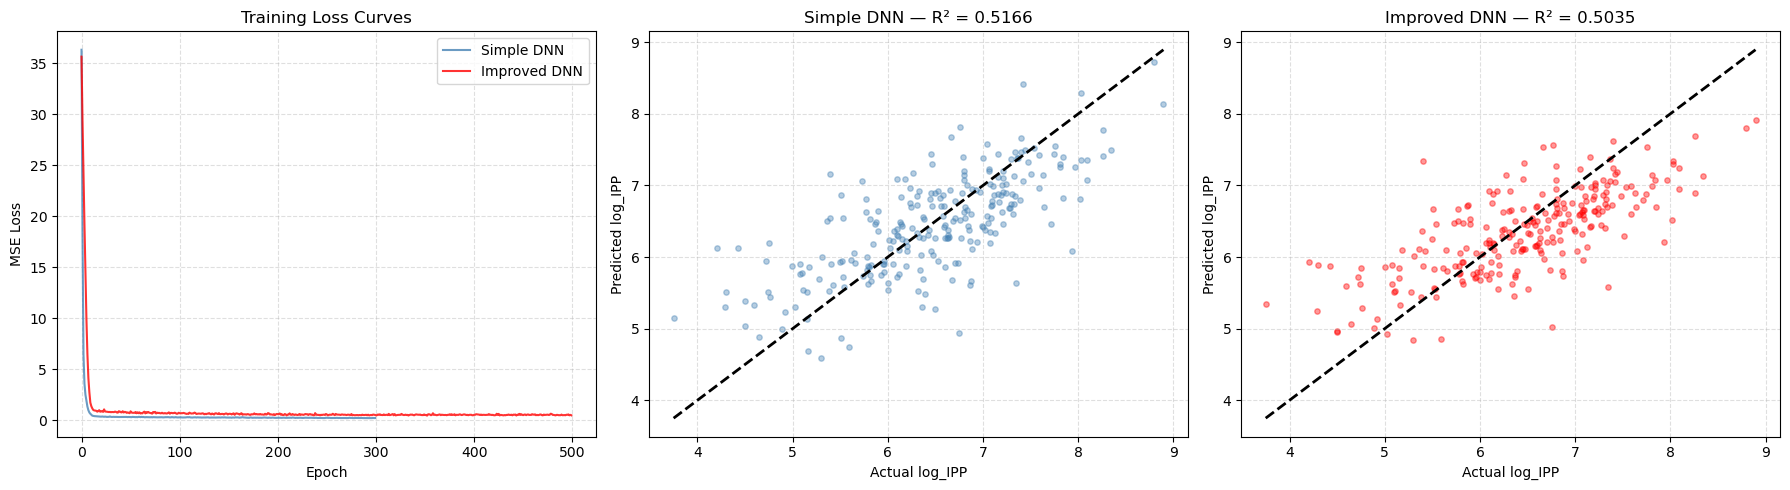

In [76]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1 — Training Loss Curves
axes[0].plot(losses1, color='steelblue', label='Simple DNN',   alpha=0.8)
axes[0].plot(losses2, color='red',       label='Improved DNN', alpha=0.8)
axes[0].set_title('Training Loss Curves')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE Loss')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.4)

# Plot 2 — Simple DNN Actual vs Predicted
axes[1].scatter(y_test, pred1, alpha=0.4, s=15, color='steelblue')
axes[1].plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'k--', linewidth=2)
axes[1].set_title(f'Simple DNN — R² = {r2_dnn1:.4f}')
axes[1].set_xlabel('Actual log_IPP')
axes[1].set_ylabel('Predicted log_IPP')
axes[1].grid(True, linestyle='--', alpha=0.4)

# Plot 3 — Improved DNN Actual vs Predicted
axes[2].scatter(y_test, pred2, alpha=0.4, s=15, color='red')
axes[2].plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()], 'k--', linewidth=2)
axes[2].set_title(f'Improved DNN — R² = {r2_dnn2:.4f}')
axes[2].set_xlabel('Actual log_IPP')
axes[2].set_ylabel('Predicted log_IPP')
axes[2].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()